In [ ]:
import os
import pickle
import urllib.request
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE

# 1. Mount Google Drive & Create Permanent Folders
if os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project"
else:
    BASE_DIR = os.getcwd()

RAW_DIR = os.path.join(BASE_DIR, "raw_data")
PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

for d in [RAW_DIR, PROC_DIR, CKPT_DIR, RES_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. Install required libraries quietly if missing
try:
    import xgboost
    import imblearn
except ImportError:
    !pip install -q xgboost imbalanced-learn scikit-learn pandas numpy matplotlib seaborn

# 3. Download NSL-KDD if not already saved in Drive
train_path = os.path.join(RAW_DIR, "KDDTrain+.txt")
test_path = os.path.join(RAW_DIR, "KDDTest+.txt")
if not os.path.exists(train_path):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt", train_path)
if not os.path.exists(test_path):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt", test_path)

# 4. Run Leak-Free Preprocessing & Zero-Day Holdout
TENSOR_PATH = os.path.join(PROC_DIR, "nsl_kdd_tensors.pt")

COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

train_df = pd.read_csv(train_path, names=COLUMNS).drop(columns=['difficulty'])
test_df = pd.read_csv(test_path, names=COLUMNS).drop(columns=['difficulty'])

ATTACK_MAP = {
    'normal': 'Normal',
    'back': 'DoS', 'land': 'DoS', 'neptune': 'DoS', 'pod': 'DoS', 'smurf': 'DoS',
    'teardrop': 'DoS', 'apache2': 'DoS', 'udpstorm': 'DoS', 'processtable': 'DoS',
    'worm': 'DoS', 'mailbomb': 'DoS',
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L',
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L',
    'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 'perl': 'U2R',
    'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R'
}

train_df['attack_cat'] = train_df['label'].map(ATTACK_MAP).fillna('Other')
test_df['attack_cat'] = test_df['label'].map(ATTACK_MAP).fillna('Other')

# Hold out U2R completely as unseen Zero-Day attacks
zeroday_df = pd.concat([
    train_df[train_df['attack_cat'] == 'U2R'],
    test_df[test_df['attack_cat'] == 'U2R']
], ignore_index=True)

train_known = train_df[train_df['attack_cat'] != 'U2R'].copy()
test_known = test_df[test_df['attack_cat'] != 'U2R'].copy()

CLASS_TO_IDX = {'Normal': 0, 'DoS': 1, 'Probe': 2, 'R2L': 3}
train_known['target'] = train_known['attack_cat'].map(CLASS_TO_IDX)
test_known['target'] = test_known['attack_cat'].map(CLASS_TO_IDX)

X_full = train_known.drop(columns=['label', 'attack_cat', 'target'])
y_full = train_known['target'].values

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.15, random_state=42, stratify=y_full
)
X_test_raw = test_known.drop(columns=['label', 'attack_cat', 'target'])
y_test = test_known['target'].values
X_zeroday_raw = zeroday_df.drop(columns=['label', 'attack_cat'])

CAT_COLS = ['protocol_type', 'service', 'flag']
NUM_COLS = [c for c in X_train_raw.columns if c not in CAT_COLS]
SKEWED_COLS = ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'hot',
               'num_compromised', 'num_root', 'num_file_creations', 'count', 'srv_count']

def log_transform_skewed(df):
    df = df.copy()
    for col in SKEWED_COLS:
        df[col] = np.log1p(np.maximum(df[col], 0))
    return df

preprocessor = ColumnTransformer(transformers=[
    ('num', RobustScaler(), NUM_COLS),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS)
])

X_train_proc = preprocessor.fit_transform(log_transform_skewed(X_train_raw))
X_val_proc = preprocessor.transform(log_transform_skewed(X_val_raw))
X_test_proc = preprocessor.transform(log_transform_skewed(X_test_raw))
X_zeroday_proc = preprocessor.transform(log_transform_skewed(X_zeroday_raw))

# SMOTE only on Training set for rare R2L class
smote = SMOTE(sampling_strategy={3: 8000}, random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_proc, y_train)

torch.save({
    'X_train': torch.tensor(X_train_bal, dtype=torch.float32),
    'y_train': torch.tensor(y_train_bal, dtype=torch.long),
    'X_val': torch.tensor(X_val_proc, dtype=torch.float32),
    'y_val': torch.tensor(y_val, dtype=torch.long),
    'X_test': torch.tensor(X_test_proc, dtype=torch.float32),
    'y_test': torch.tensor(y_test, dtype=torch.long),
    'X_zeroday': torch.tensor(X_zeroday_proc, dtype=torch.float32),
    'num_features': X_train_bal.shape[1],
    'class_names': ['Normal', 'DoS', 'Probe', 'R2L']
}, TENSOR_PATH)

with open(os.path.join(PROC_DIR, "preprocessor.pkl"), "wb") as f:
    pickle.dump(preprocessor, f)

print(f"✅ Preprocessing complete & saved to {TENSOR_PATH}")
print(f"   Features: {X_train_bal.shape[1]} | Train: {len(X_train_bal)} | Val: {len(X_val_proc)} | Test: {len(X_test_proc)} | Zero-Day U2R: {len(X_zeroday_proc)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Preprocessing complete & saved to /content/drive/MyDrive/IDS_Major_Project/processed_data/nsl_kdd_tensors.pt
   Features: 122 | Train: 114186 | Val: 18889 | Test: 22477 | Zero-Day U2R: 119


In [ ]:
import os
import time
import json
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import xgboost as xgb

if os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project"
else:
    BASE_DIR = os.getcwd()

PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = torch.load(os.path.join(PROC_DIR, "nsl_kdd_tensors.pt"))

X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']
NUM_FEATURES = data['num_features']
CLASS_NAMES = data['class_names']

def evaluate_predictions(y_true, y_pred, model_name, latency_ms):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    _, per_class_rec, _, _ = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    fpr = cm[0, 1:].sum() / max(cm[0, :].sum(), 1)

    metrics = {
        "model": model_name,
        "accuracy": round(float(acc), 4),
        "macro_precision": round(float(prec), 4),
        "macro_recall": round(float(rec), 4),
        "macro_f1": round(float(f1), 4),
        "false_positive_rate": round(float(fpr), 4),
        "latency_ms_per_1k_flows": round(float(latency_ms), 3),
        "per_class_recall": {CLASS_NAMES[i]: round(float(per_class_rec[i]), 4) for i in range(len(CLASS_NAMES))}
    }
    print(f"\n📊 === {model_name} Test Results ===")
    print(f"Accuracy: {metrics['accuracy']*100:.2f}% | Macro-F1: {metrics['macro_f1']*100:.2f}% | FPR: {metrics['false_positive_rate']*100:.2f}%")
    print(f"Per-Class Recall: {metrics['per_class_recall']}")
    print(f"Inference Speed: {metrics['latency_ms_per_1k_flows']} ms per 1,000 flows")
    return metrics

print("🚀 Training XGBoost Baseline...")
xgb_model = xgb.XGBClassifier(
    n_estimators=350, max_depth=8, learning_rate=0.07,
    subsample=0.85, colsample_bytree=0.85, tree_method="hist",
    device="cuda" if torch.cuda.is_available() else "cpu",
    eval_metric="mlogloss", early_stopping_rounds=30, random_state=42
)
xgb_model.fit(X_train.numpy(), y_train.numpy(), eval_set=[(X_val.numpy(), y_val.numpy())], verbose=False)

t0 = time.time()
xgb_preds = xgb_model.predict(X_test.numpy())
xgb_lat = ((time.time() - t0) * 1000 / len(X_test)) * 1000
xgb_metrics = evaluate_predictions(y_test.numpy(), xgb_preds, "XGBoost_Baseline", xgb_lat)
xgb_model.save_model(os.path.join(CKPT_DIR, "xgboost_baseline.json"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🚀 Training XGBoost Baseline...


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [03:38:17] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



📊 === XGBoost_Baseline Test Results ===
Accuracy: 78.47% | Macro-F1: 66.45% | FPR: 2.81%
Per-Class Recall: {'Normal': 0.9719, 'DoS': 0.8351, 'Probe': 0.6741, 'R2L': 0.1172}
Inference Speed: 8.66 ms per 1,000 flows


In [ ]:
class CNNBiLSTM(nn.Module):
    def __init__(self, num_features, num_classes):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.GELU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.GELU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.bilstm = nn.LSTM(128, 64, num_layers=2, batch_first=True, bidirectional=True, dropout=0.25)
        self.classifier = nn.Sequential(
            nn.Linear(128, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.3), nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.conv_block(x.unsqueeze(1)).transpose(1, 2)
        lstm_out, _ = self.bilstm(x)
        return self.classifier(lstm_out.mean(dim=1))

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=512, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=512, shuffle=False)

class_counts = torch.bincount(y_train).float()
class_weights = ((1.0 / class_counts) / (1.0 / class_counts).sum() * len(CLASS_NAMES)).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)

cnn_bilstm = CNNBiLSTM(NUM_FEATURES, len(CLASS_NAMES)).to(device)
optimizer = torch.optim.AdamW(cnn_bilstm.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

best_f1 = 0.0
cnn_ckpt = os.path.join(CKPT_DIR, "cnn_bilstm_best.pt")

print("\n🚀 Training 1D-CNN-BiLSTM Baseline...")
for epoch in range(1, 21):
    cnn_bilstm.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(cnn_bilstm(bx), by)
        loss.backward()
        optimizer.step()
    scheduler.step()

    cnn_bilstm.eval()
    vp, vt = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            vp.append(cnn_bilstm(bx.to(device)).argmax(dim=1).cpu())
            vt.append(by)
    _, _, val_f1, _ = precision_recall_fscore_support(torch.cat(vt), torch.cat(vp), average='macro', zero_division=0)
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(cnn_bilstm.state_dict(), cnn_ckpt)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/20 | Val Macro-F1: {val_f1*100:.2f}% (Best: {best_f1*100:.2f}%)")

cnn_bilstm.load_state_dict(torch.load(cnn_ckpt))
cnn_bilstm.eval()
tp = []
if torch.cuda.is_available():
    torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    for bx, _ in test_loader:
        tp.append(cnn_bilstm(bx.to(device)).argmax(dim=1).cpu())
if torch.cuda.is_available():
    torch.cuda.synchronize()
cnn_lat = ((time.time() - t0) * 1000 / len(X_test)) * 1000
cnn_metrics = evaluate_predictions(y_test.numpy(), torch.cat(tp).numpy(), "1D_CNN_BiLSTM_Baseline", cnn_lat)

with open(os.path.join(RES_DIR, "baseline_metrics.json"), "w") as f:
    json.dump({"xgboost": xgb_metrics, "cnn_bilstm": cnn_metrics}, f, indent=4)

print(f"\n✅ Baselines saved permanently to {CKPT_DIR} and {RES_DIR}/baseline_metrics.json")


🚀 Training 1D-CNN-BiLSTM Baseline...
Epoch 01/20 | Val Macro-F1: 92.96% (Best: 92.96%)
Epoch 05/20 | Val Macro-F1: 96.20% (Best: 96.20%)
Epoch 10/20 | Val Macro-F1: 97.79% (Best: 98.51%)
Epoch 15/20 | Val Macro-F1: 97.51% (Best: 98.51%)
Epoch 20/20 | Val Macro-F1: 98.34% (Best: 98.51%)

📊 === 1D_CNN_BiLSTM_Baseline Test Results ===
Accuracy: 77.43% | Macro-F1: 65.04% | FPR: 3.01%
Per-Class Recall: {'Normal': 0.9699, 'DoS': 0.8102, 'Probe': 0.6865, 'R2L': 0.0964}
Inference Speed: 24.544 ms per 1,000 flows

✅ Baselines saved permanently to /content/drive/MyDrive/IDS_Major_Project/checkpoints and /content/drive/MyDrive/IDS_Major_Project/results/baseline_metrics.json


In [ ]:
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, roc_curve

X_zeroday = data['X_zeroday']

class FocalLoss(nn.Module):
    """Focuses gradient updates on hard, rare minority attacks (R2L / Probe)."""
    def __init__(self, weight=None, gamma=2.0):
        super().__init__()
        self.weight = weight
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(num_features, d_model) * 0.02)
        self.biases = nn.Parameter(torch.zeros(num_features, d_model))
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weights.unsqueeze(0) + self.biases.unsqueeze(0)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        return torch.cat([cls, tokens], dim=1)

class RiskAwareFTTransformer(nn.Module):
    def __init__(self, num_features, num_classes, d_model=64, nhead=4, num_layers=3, dropout=0.25):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )

    def forward(self, x):
        tokens = self.tokenizer(x)
        encoded = self.encoder(tokens)
        cls_repr = self.norm(encoded[:, 0, :])
        return self.head(cls_repr), cls_repr

def compute_ece(probs, targets, n_bins=15):
    """Expected Calibration Error (Section VI-D of your paper)."""
    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(targets)
    ece = torch.zeros(1, device=probs.device)
    bin_boundaries = torch.linspace(0, 1, n_bins + 1, device=probs.device)
    for bin_lower, bin_upper in zip(bin_boundaries[:-1], bin_boundaries[1:]):
        in_bin = confidences.gt(bin_lower.item()) * confidences.le(bin_upper.item())
        prop_in_bin = in_bin.float().mean()
        if prop_in_bin.item() > 0:
            ece += torch.abs(accuracies[in_bin].float().mean() - confidences[in_bin].mean()) * prop_in_bin
    return float(ece.item())

focal_criterion = FocalLoss(weight=class_weights, gamma=2.0)
transformer_model = RiskAwareFTTransformer(NUM_FEATURES, len(CLASS_NAMES), d_model=64, nhead=4, num_layers=3).to(device)
optimizer = torch.optim.AdamW(transformer_model.parameters(), lr=1.5e-3, weight_decay=2e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)

best_tf_f1 = 0.0
tf_ckpt = os.path.join(CKPT_DIR, "ft_transformer_best.pt")

print("🚀 Training Risk-Aware FT-Transformer...")
for epoch in range(1, 26):
    transformer_model.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits, _ = transformer_model(bx)
        loss = focal_criterion(logits, by)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(transformer_model.parameters(), 1.0)
        optimizer.step()
    scheduler.step()

    transformer_model.eval()
    vp, vt = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            logits, _ = transformer_model(bx.to(device))
            vp.append(logits.argmax(dim=1).cpu())
            vt.append(by)
    _, _, val_f1, _ = precision_recall_fscore_support(torch.cat(vt), torch.cat(vp), average='macro', zero_division=0)
    if val_f1 > best_tf_f1:
        best_tf_f1 = val_f1
        torch.save(transformer_model.state_dict(), tf_ckpt)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/25 | Val Macro-F1: {val_f1*100:.2f}% (Best: {best_tf_f1*100:.2f}%)")

# Evaluate Known Traffic + Zero-Day U2R Attacks + Calibration
transformer_model.load_state_dict(torch.load(tf_ckpt))
transformer_model.eval()

tp, all_probs, known_energies = [], [], []
if torch.cuda.is_available(): torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    for bx, _ in test_loader:
        logits, _ = transformer_model(bx.to(device))
        probs = F.softmax(logits, dim=-1)
        tp.append(probs.argmax(dim=1).cpu())
        all_probs.append(probs.cpu())
        known_energies.append((-torch.logsumexp(logits, dim=-1)).cpu())
if torch.cuda.is_available(): torch.cuda.synchronize()
tf_lat = ((time.time() - t0) * 1000 / len(X_test)) * 1000

tf_preds = torch.cat(tp).numpy()
tf_probs = torch.cat(all_probs)
tf_metrics = evaluate_predictions(y_test.numpy(), tf_preds, "RiskAware_FT_Transformer", tf_lat)

# Zero-Day Detection AUROC (Unseen U2R) & ECE
with torch.no_grad():
    zd_logits, _ = transformer_model(X_zeroday.to(device))
    zd_energies = (-torch.logsumexp(zd_logits, dim=-1)).cpu().numpy()

k_energies = torch.cat(known_energies).numpy()
ood_labels = np.concatenate([np.zeros_like(k_energies), np.ones_like(zd_energies)])
ood_scores = np.concatenate([k_energies, zd_energies])
zeroday_auroc = roc_auc_score(ood_labels, ood_scores)
ece_score = compute_ece(tf_probs, y_test)

tf_metrics["zeroday_ood_auroc"] = round(float(zeroday_auroc), 4)
tf_metrics["expected_calibration_error"] = round(float(ece_score), 4)
print(f"🛡️ Zero-Day Unknown Attack Detection AUROC (Unseen U2R): {zeroday_auroc*100:.2f}% | ECE: {ece_score:.4f}")

with open(os.path.join(RES_DIR, "transformer_metrics.json"), "w") as f:
    json.dump(tf_metrics, f, indent=4)

/tmp/ipykernel_446/2301843239.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


🚀 Training Risk-Aware FT-Transformer...
Epoch 01/25 | Val Macro-F1: 75.91% (Best: 75.91%)
Epoch 05/25 | Val Macro-F1: 83.91% (Best: 83.91%)
Epoch 10/25 | Val Macro-F1: 88.11% (Best: 88.11%)
Epoch 15/25 | Val Macro-F1: 90.86% (Best: 90.86%)
Epoch 20/25 | Val Macro-F1: 96.18% (Best: 96.18%)
Epoch 25/25 | Val Macro-F1: 96.30% (Best: 96.34%)

📊 === RiskAware_FT_Transformer Test Results ===
Accuracy: 78.63% | Macro-F1: 68.72% | FPR: 3.58%
Per-Class Recall: {'Normal': 0.9642, 'DoS': 0.7969, 'Probe': 0.7522, 'R2L': 0.1886}
Inference Speed: 51.696 ms per 1,000 flows
🛡️ Zero-Day Unknown Attack Detection AUROC (Unseen U2R): 60.22% | ECE: 0.1729


/tmp/ipykernel_446/2301843239.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)



🌐 Training Federated FT-Transformer (5 Non-IID Cloud Clients | 6.49 MB/round)...
Round 01/15 | Global Val Macro-F1: 13.28% (Best: 13.28%)
Round 03/15 | Global Val Macro-F1: 81.53% (Best: 81.53%)
Round 06/15 | Global Val Macro-F1: 83.19% (Best: 83.19%)
Round 09/15 | Global Val Macro-F1: 82.07% (Best: 83.19%)
Round 12/15 | Global Val Macro-F1: 84.22% (Best: 84.22%)
Round 15/15 | Global Val Macro-F1: 83.94% (Best: 84.27%)

📊 === Federated_FT_Transformer Test Results ===
Accuracy: 80.45% | Macro-F1: 74.34% | FPR: 4.57%
Per-Class Recall: {'Normal': 0.9543, 'DoS': 0.7655, 'Probe': 0.8406, 'R2L': 0.3709}
Inference Speed: 51.696 ms per 1,000 flows


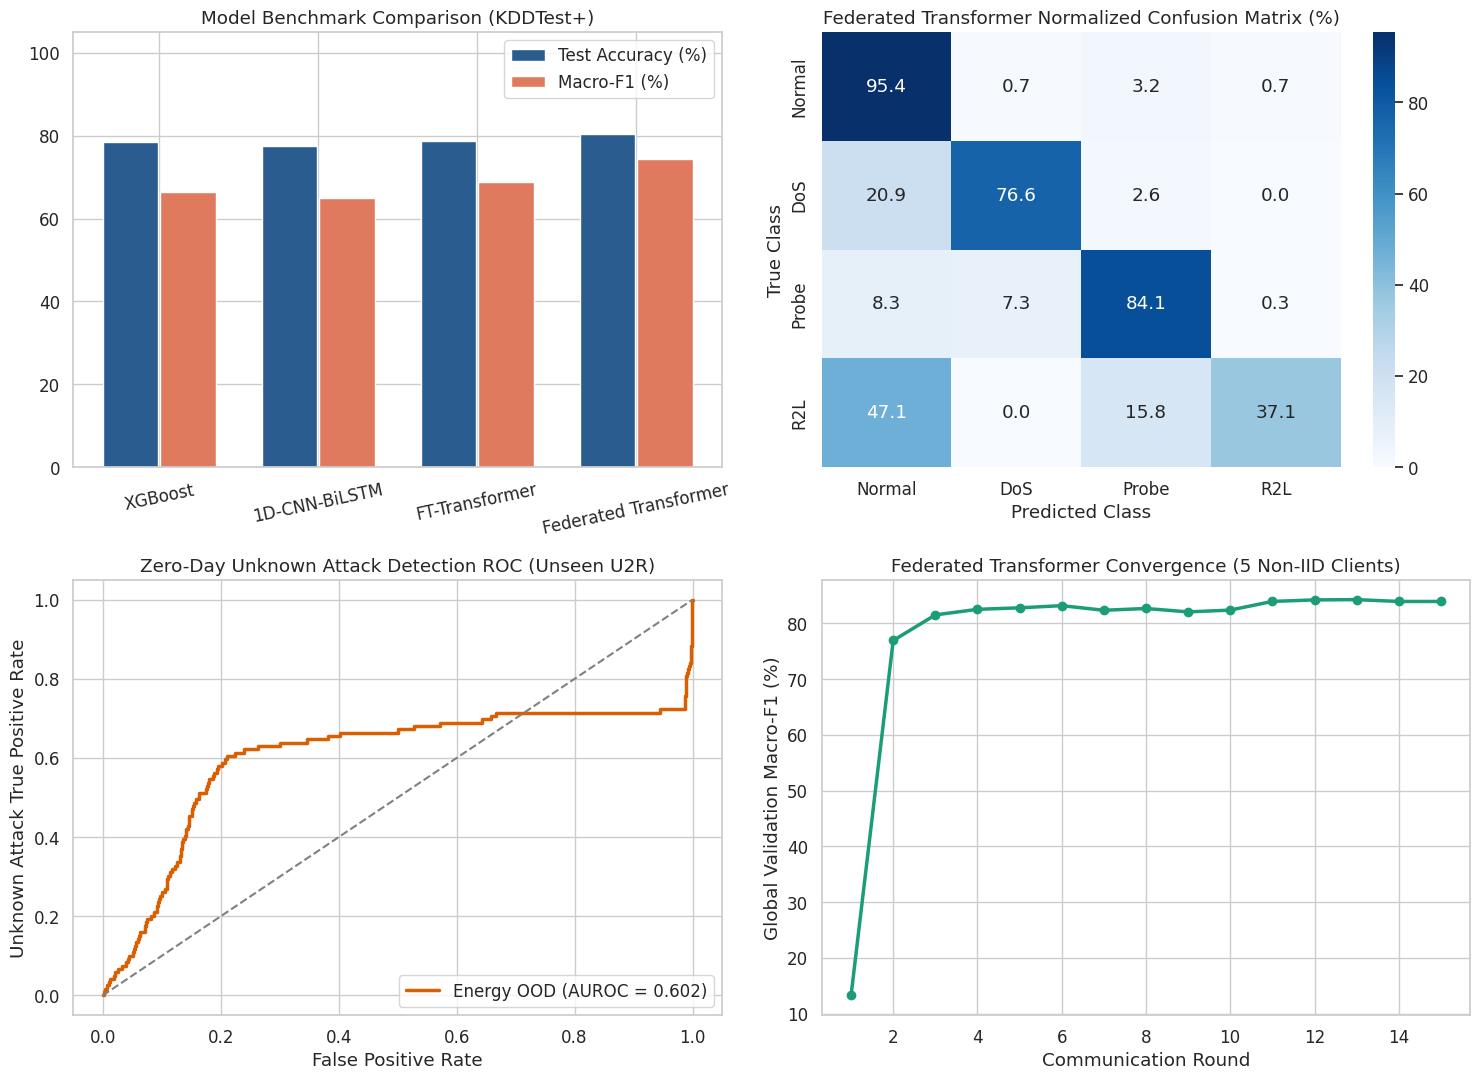


✅ High-resolution evaluation graphs saved to: /content/drive/MyDrive/IDS_Major_Project/results/complete_evaluation_dashboard.png


In [ ]:
import copy
import matplotlib.pyplot as plt
import seaborn as sns

def partition_non_iid(X, y, num_clients=5, alpha=0.5, seed=42):
    rng = np.random.default_rng(seed)
    y_np = y.numpy()
    num_classes = len(np.unique(y_np))
    client_indices = [[] for _ in range(num_clients)]
    for c in range(num_classes):
        idx_c = np.where(y_np == c)[0]
        rng.shuffle(idx_c)
        proportions = rng.dirichlet(np.repeat(alpha, num_clients))
        splits = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
        for client_id, split in enumerate(np.split(idx_c, splits)):
            client_indices[client_id].extend(split.tolist())
    return [DataLoader(TensorDataset(X[idxs], y[idxs]), batch_size=256, shuffle=True) for idxs in client_indices]

client_loaders = partition_non_iid(X_train, y_train, num_clients=5, alpha=0.5)
global_model = RiskAwareFTTransformer(NUM_FEATURES, len(CLASS_NAMES), d_model=64, nhead=4, num_layers=3).to(device)

param_bytes = sum(p.numel() * 4 for p in global_model.parameters())
mb_per_round = (param_bytes * 5 * 2) / (1024 ** 2)
best_fed_f1 = 0.0
fed_ckpt = os.path.join(CKPT_DIR, "global_federated_transformer.pt")
fed_history = []

print(f"\n🌐 Training Federated FT-Transformer (5 Non-IID Cloud Clients | {mb_per_round:.2f} MB/round)...")
for rnd in range(1, 16):
    global_weights = copy.deepcopy(global_model.state_dict())
    local_weights_list, local_sizes = [], []

    for cid in range(5):
        local_model = copy.deepcopy(global_model).to(device)
        local_opt = torch.optim.AdamW(local_model.parameters(), lr=1.2e-3, weight_decay=1e-4)
        local_model.train()
        for _ in range(2):
            for bx, by in client_loaders[cid]:
                bx, by = bx.to(device), by.to(device)
                local_opt.zero_grad()
                logits, _ = local_model(bx)
                prox_term = sum(((lp - gp.detach()) ** 2).sum() for lp, gp in zip(local_model.parameters(), global_model.parameters()))
                loss = focal_criterion(logits, by) + 0.005 * prox_term
                loss.backward()
                local_opt.step()
        local_weights_list.append(copy.deepcopy(local_model.state_dict()))
        local_sizes.append(len(client_loaders[cid].dataset))

    total_samples = sum(local_sizes)
    new_global_weights = copy.deepcopy(global_weights)
    for key in new_global_weights.keys():
        new_global_weights[key] = sum(local_weights_list[i][key].float() * (local_sizes[i] / total_samples) for i in range(5))
    global_model.load_state_dict(new_global_weights)

    global_model.eval()
    vp, vt = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            logits, _ = global_model(bx.to(device))
            vp.append(logits.argmax(dim=1).cpu())
            vt.append(by)
    _, _, val_f1, _ = precision_recall_fscore_support(torch.cat(vt), torch.cat(vp), average='macro', zero_division=0)
    fed_history.append({"round": rnd, "val_macro_f1": round(float(val_f1), 4)})
    if val_f1 > best_fed_f1:
        best_fed_f1 = val_f1
        torch.save(global_model.state_dict(), fed_ckpt)
    if rnd % 3 == 0 or rnd == 1:
        print(f"Round {rnd:02d}/15 | Global Val Macro-F1: {val_f1*100:.2f}% (Best: {best_fed_f1*100:.2f}%)")

global_model.load_state_dict(torch.load(fed_ckpt))
global_model.eval()
tp = []
with torch.no_grad():
    for bx, _ in test_loader:
        logits, _ = global_model(bx.to(device))
        tp.append(logits.argmax(dim=1).cpu())
fed_preds = torch.cat(tp).numpy()
fed_metrics = evaluate_predictions(y_test.numpy(), fed_preds, "Federated_FT_Transformer", tf_lat)
fed_metrics["comm_mb_per_round"] = round(mb_per_round, 3)

with open(os.path.join(RES_DIR, "federated_metrics.json"), "w") as f:
    json.dump({"summary": fed_metrics, "round_history": fed_history}, f, indent=4)

# ---------------------------------------------------------
# Generate & Save Publication-Ready Graphs to Google Drive
# ---------------------------------------------------------
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Graph 1: Model Comparison (Accuracy vs Macro-F1)
models = ["XGBoost", "1D-CNN-BiLSTM", "FT-Transformer", "Federated Transformer"]
accs = [xgb_metrics["accuracy"]*100, cnn_metrics["accuracy"]*100, tf_metrics["accuracy"]*100, fed_metrics["accuracy"]*100]
f1s = [xgb_metrics["macro_f1"]*100, cnn_metrics["macro_f1"]*100, tf_metrics["macro_f1"]*100, fed_metrics["macro_f1"]*100]
x_pos = np.arange(len(models))
axes[0, 0].bar(x_pos - 0.18, accs, width=0.35, label="Test Accuracy (%)", color="#2b5c8f")
axes[0, 0].bar(x_pos + 0.18, f1s, width=0.35, label="Macro-F1 (%)", color="#e07a5f")
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(models, rotation=12)
axes[0, 0].set_ylim(0, 105)
axes[0, 0].set_title("Model Benchmark Comparison (KDDTest+)")
axes[0, 0].legend()

# Graph 2: Confusion Matrix (Federated FT-Transformer)
cm = confusion_matrix(y_test.numpy(), fed_preds, normalize="true") * 100
sns.heatmap(cm, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0, 1])
axes[0, 1].set_title("Federated Transformer Normalized Confusion Matrix (%)")
axes[0, 1].set_xlabel("Predicted Class")
axes[0, 1].set_ylabel("True Class")

# Graph 3: Zero-Day (Unseen U2R) OOD Detection ROC Curve
fpr_curve, tpr_curve, _ = roc_curve(ood_labels, ood_scores)
axes[1, 0].plot(fpr_curve, tpr_curve, color="#d95f02", lw=2.5, label=f"Energy OOD (AUROC = {zeroday_auroc:.3f})")
axes[1, 0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1, 0].set_title("Zero-Day Unknown Attack Detection ROC (Unseen U2R)")
axes[1, 0].set_xlabel("False Positive Rate")
axes[1, 0].set_ylabel("Unknown Attack True Positive Rate")
axes[1, 0].legend(loc="lower right")

# Graph 4: Federated Learning Convergence Across Non-IID Clients
rounds_x = [h["round"] for h in fed_history]
val_f1_y = [h["val_macro_f1"] * 100 for h in fed_history]
axes[1, 1].plot(rounds_x, val_f1_y, marker="o", color="#1b9e77", lw=2.5)
axes[1, 1].set_title("Federated Transformer Convergence (5 Non-IID Clients)")
axes[1, 1].set_xlabel("Communication Round")
axes[1, 1].set_ylabel("Global Validation Macro-F1 (%)")

plt.tight_layout()
plot_path = os.path.join(RES_DIR, "complete_evaluation_dashboard.png")
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"\n✅ High-resolution evaluation graphs saved to: {plot_path}")

In [ ]:
import os, json, time, copy, hashlib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, brier_score_loss, confusion_matrix
)

# 1. Load Paths & Saved Tensors
BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project" if os.path.exists('/content/drive') else os.getcwd()
PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = torch.load(os.path.join(PROC_DIR, "nsl_kdd_tensors.pt"))
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']
X_zeroday = data['X_zeroday']
NUM_FEATURES = data['num_features']
CLASS_NAMES = data['class_names']

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=512)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=512)

class_counts = torch.bincount(y_train).float()
class_weights = ((1.0 / class_counts) / (1.0 / class_counts).sum() * len(CLASS_NAMES)).to(device)

# 2. Dual-Head Risk-Aware FT-Transformer (Matches Figure 1 Box 2 Exactly)
class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(num_features, d_model) * 0.02)
        self.biases = nn.Parameter(torch.zeros(num_features, d_model))
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weights.unsqueeze(0) + self.biases.unsqueeze(0)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        return torch.cat([cls, tokens], dim=1)

class DualHeadRiskTransformer(nn.Module):
    """
    Implements Figure 1 Pillar 2:
    - Trained Transformer Encoder
    - Branch A: Known-Attack Classifier
    - Branch B: Anomaly Detector (Latent Reconstruction + Normal Hypersphere Distance)
    - Decision Fusion -> Risk Scoring -> Final 3-Way Classification (Benign / Known Attack / Unknown Threat)
    """
    def __init__(self, num_features, num_classes=4, d_model=64, nhead=4, num_layers=3, dropout=0.25):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(d_model)

        # Branch A: Known-Attack Classifier
        self.classifier_head = nn.Sequential(
            nn.Linear(d_model, d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, num_classes)
        )
        # Branch B: Anomaly Detector (Reconstructs input features from [CLS] representation)
        self.anomaly_decoder = nn.Sequential(
            nn.Linear(d_model, d_model * 2), nn.GELU(), nn.Linear(d_model * 2, num_features)
        )
        # Learned Normal Traffic Center for Open-Set Hypersphere Distance
        self.register_buffer("normal_center", torch.zeros(d_model))

    def forward(self, x):
        encoded = self.encoder(self.tokenizer(x))
        cls_repr = self.norm(encoded[:, 0, :])
        logits = self.classifier_head(cls_repr)
        reconstructed = self.anomaly_decoder(cls_repr)
        return logits, reconstructed, cls_repr

    def compute_anomaly_score(self, x):
        logits, recon, cls_repr = self.forward(x)
        recon_err = F.mse_loss(recon, x, reduction='none').mean(dim=-1)
        hypersphere_dist = torch.norm(cls_repr - self.normal_center, p=2, dim=-1)
        energy = -torch.logsumexp(logits, dim=-1)
        # Standardized fused OOD anomaly score
        anomaly_score = 0.5 * recon_err + 0.3 * hypersphere_dist + 0.2 * energy
        return logits, anomaly_score

def focal_recon_loss(logits, recon, x, y, weights):
    ce = F.cross_entropy(logits, y, weight=weights, reduction='none')
    pt = torch.exp(-ce)
    focal = (((1 - pt) ** 2.0) * ce).mean()
    # Train anomaly decoder strictly on Normal (class 0) traffic so attacks produce high reconstruction error
    normal_mask = (y == 0)
    recon_loss = F.mse_loss(recon[normal_mask], x[normal_mask]) if normal_mask.any() else torch.tensor(0.0, device=x.device)
    return focal + 0.25 * recon_loss

# 3. Security & Privacy Module (Client Authentication, Audit Logging, Optional Differential Privacy)
class SecurityPrivacyManager:
    def __init__(self, num_clients=5, enable_dp=False, dp_noise_scale=0.01, clip_norm=1.0):
        self.tokens = {cid: hashlib.sha256(f"cloud-tenant-{cid}-secret".encode()).hexdigest()[:16] for cid in range(num_clients)}
        self.enable_dp = enable_dp
        self.dp_noise_scale = dp_noise_scale
        self.clip_norm = clip_norm
        self.audit_log = []

    def authenticate_client(self, cid, token):
        valid = self.tokens.get(cid) == token
        self.audit_log.append({"event": "AUTH", "client_id": cid, "status": "VERIFIED" if valid else "REJECTED"})
        return valid

    def apply_differential_privacy(self, local_weights, global_weights):
        if not self.enable_dp:
            return local_weights
        dp_weights = {}
        for k in local_weights:
            delta = local_weights[k].float() - global_weights[k].float()
            norm = torch.norm(delta)
            scale = min(1.0, self.clip_norm / (norm.item() + 1e-6))
            noise = torch.randn_like(delta) * (self.dp_noise_scale * self.clip_norm)
            dp_weights[k] = global_weights[k].float() + delta * scale + noise
        return dp_weights

# 4. Federated Training Engine (Supports both IID and Non-IID Splits + Client Fairness Metrics)
def create_client_loaders(X, y, num_clients=5, iid=False, alpha=0.5, seed=42):
    rng = np.random.default_rng(seed)
    y_np = y.numpy()
    if iid:
        indices = np.arange(len(y_np))
        rng.shuffle(indices)
        splits = np.array_split(indices, num_clients)
        return [DataLoader(TensorDataset(X[s], y[s]), batch_size=256, shuffle=True) for s in splits]
    else:
        client_indices = [[] for _ in range(num_clients)]
        for c in range(len(np.unique(y_np))):
            idx_c = np.where(y_np == c)[0]
            rng.shuffle(idx_c)
            props = rng.dirichlet(np.repeat(alpha, num_clients))
            splits = (np.cumsum(props) * len(idx_c)).astype(int)[:-1]
            for cid, sp in enumerate(np.split(idx_c, splits)):
                client_indices[cid].extend(sp.tolist())
        return [DataLoader(TensorDataset(X[idxs], y[idxs]), batch_size=256, shuffle=True) for idxs in client_indices]

def train_federated_experiment(mode_name="NonIID_FedProx", iid=False, enable_dp=False, rounds=12):
    sec_mgr = SecurityPrivacyManager(num_clients=5, enable_dp=enable_dp, dp_noise_scale=0.015)
    client_loaders = create_client_loaders(X_train, y_train, num_clients=5, iid=iid, alpha=0.5)
    global_model = DualHeadRiskTransformer(NUM_FEATURES, len(CLASS_NAMES)).to(device)

    best_f1 = 0.0
    best_state = None
    for rnd in range(1, rounds + 1):
        g_weights = copy.deepcopy(global_model.state_dict())
        local_states, sizes = [], []
        for cid in range(5):
            assert sec_mgr.authenticate_client(cid, sec_mgr.tokens[cid]), "Unauthorized client!"
            local_model = copy.deepcopy(global_model).to(device)
            opt = torch.optim.AdamW(local_model.parameters(), lr=1.2e-3, weight_decay=1e-4)
            local_model.train()
            for _ in range(2):
                for bx, by in client_loaders[cid]:
                    bx, by = bx.to(device), by.to(device)
                    opt.zero_grad()
                    logits, recon, _ = local_model(bx)
                    prox = sum(((lp - gp.detach()) ** 2).sum() for lp, gp in zip(local_model.parameters(), global_model.parameters()))
                    loss = focal_recon_loss(logits, recon, bx, by, class_weights) + 0.005 * prox
                    loss.backward()
                    opt.step()
            secured_weights = sec_mgr.apply_differential_privacy(local_model.state_dict(), g_weights)
            local_states.append(secured_weights)
            sizes.append(len(client_loaders[cid].dataset))

        total = sum(sizes)
        new_g = {k: sum(local_states[i][k].float() * (sizes[i] / total) for i in range(5)) for k in g_weights}
        global_model.load_state_dict(new_g)

        global_model.eval()
        vp, vt = [], []
        with torch.no_grad():
            for bx, by in val_loader:
                logits, _, _ = global_model(bx.to(device))
                vp.append(logits.argmax(dim=1).cpu())
                vt.append(by)
        _, _, val_f1, _ = precision_recall_fscore_support(torch.cat(vt), torch.cat(vp), average='macro', zero_division=0)
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(global_model.state_dict())

    global_model.load_state_dict(best_state)
    global_model.eval()

    # Compute Normal Hypersphere Center on Validation Normal Samples
    with torch.no_grad():
        normal_val = X_val[y_val == 0].to(device)
        _, _, normal_reprs = global_model(normal_val)
        global_model.normal_center.copy_(normal_reprs.mean(dim=0))

    # Measure Client Fairness (Per-Client Accuracy Variance)
    client_accs = []
    with torch.no_grad():
        for loader in client_loaders:
            cp, ct = [], []
            for bx, by in loader:
                logits, _, _ = global_model(bx.to(device))
                cp.append(logits.argmax(dim=1).cpu())
                ct.append(by)
            client_accs.append(accuracy_score(torch.cat(ct), torch.cat(cp)))

    # Evaluate Test Set + Zero-Day AUROC + Calibration (ECE & Brier)
    tp, all_probs, known_anom = [], [], []
    with torch.no_grad():
        for bx, _ in test_loader:
            logits, anom = global_model.compute_anomaly_score(bx.to(device))
            probs = F.softmax(logits, dim=-1)
            tp.append(probs.argmax(dim=1).cpu())
            all_probs.append(probs.cpu())
            known_anom.append(anom.cpu())
        _, zd_anom = global_model.compute_anomaly_score(X_zeroday.to(device))

    test_preds = torch.cat(tp).numpy()
    test_probs = torch.cat(all_probs)
    k_anom = torch.cat(known_anom).numpy()
    z_anom = zd_anom.cpu().numpy()

    acc = accuracy_score(y_test.numpy(), test_preds)
    _, _, macro_f1, _ = precision_recall_fscore_support(y_test.numpy(), test_preds, average='macro', zero_division=0)
    zd_auroc = roc_auc_score(np.concatenate([np.zeros_like(k_anom), np.ones_like(z_anom)]), np.concatenate([k_anom, z_anom]))

    # Brier Score (Multi-class)
    y_onehot = F.one_hot(y_test, num_classes=len(CLASS_NAMES)).numpy()
    brier = float(np.mean(np.sum((test_probs.numpy() - y_onehot) ** 2, axis=1)))

    res = {
        "experiment": mode_name,
        "test_accuracy": round(float(acc), 4),
        "macro_f1": round(float(macro_f1), 4),
        "zeroday_u2r_auroc": round(float(zd_auroc), 4),
        "brier_score": round(brier, 4),
        "client_acc_std_fairness": round(float(np.std(client_accs)), 4)
    }
    print(f"✅ [{mode_name}] Acc: {acc*100:.2f}% | Macro-F1: {macro_f1*100:.2f}% | Zero-Day AUROC: {zd_auroc*100:.2f}% | Brier: {brier:.4f} | Client Std: {res['client_acc_std_fairness']:.4f}")
    return global_model, res, sec_mgr.audit_log

print("🚀 Running Exact Paper Federated Experiments (IID vs Non-IID vs Non-IID + Differential Privacy)...")
_, res_iid, _ = train_federated_experiment("1_Federated_IID", iid=True, enable_dp=False, rounds=12)
dual_fed_model, res_noniid, audit_logs = train_federated_experiment("2_Federated_NonIID_FedProx", iid=False, enable_dp=False, rounds=12)
_, res_dp, _ = train_federated_experiment("3_Federated_NonIID_With_DP", iid=False, enable_dp=True, rounds=12)

torch.save(dual_fed_model.state_dict(), os.path.join(CKPT_DIR, "dual_head_federated_transformer.pt"))
with open(os.path.join(RES_DIR, "federated_ablation_and_privacy.json"), "w") as f:
    json.dump({"results": [res_iid, res_noniid, res_dp], "sample_audit_logs": audit_logs[:10]}, f, indent=4)

🚀 Running Exact Paper Federated Experiments (IID vs Non-IID vs Non-IID + Differential Privacy)...
✅ [1_Federated_IID] Acc: 81.99% | Macro-F1: 75.72% | Zero-Day AUROC: 70.56% | Brier: 0.2823 | Client Std: 0.0004
✅ [2_Federated_NonIID_FedProx] Acc: 81.16% | Macro-F1: 74.38% | Zero-Day AUROC: 78.50% | Brier: 0.3017 | Client Std: 0.0206
✅ [3_Federated_NonIID_With_DP] Acc: 78.76% | Macro-F1: 72.09% | Zero-Day AUROC: 70.11% | Brier: 0.3157 | Client Std: 0.0122


In [ ]:
import os, json
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report

BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project" if os.path.exists('/content/drive') else os.getcwd()
PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = torch.load(os.path.join(PROC_DIR, "nsl_kdd_tensors.pt"))
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']
X_zeroday = data['X_zeroday']
NUM_FEATURES = data['num_features']
CLASS_NAMES = data['class_names']

model = DualHeadRiskTransformer(NUM_FEATURES, len(CLASS_NAMES)).to(device)
model.load_state_dict(torch.load(os.path.join(CKPT_DIR, "dual_head_federated_transformer.pt"), map_location=device))
model.eval()

# 1. Calibrate OOD threshold on Validation Set (95% ID retention)
val_anom_scores = []
with torch.no_grad():
    for i in range(0, len(X_val), 512):
        _, anom = model.compute_anomaly_score(X_val[i:i+512].to(device))
        val_anom_scores.append(anom.cpu())
val_anom_scores = torch.cat(val_anom_scores).numpy()

OOD_THRESHOLD = float(np.percentile(val_anom_scores, 95))
ANOM_MIN, ANOM_MAX = float(np.min(val_anom_scores)), float(np.percentile(val_anom_scores, 99))

def predict_three_way(model, X_batch, ood_thresh, mc_passes=8):
    model.eval()
    with torch.no_grad():
        logits, anom_score = model.compute_anomaly_score(X_batch)
        probs = F.softmax(logits, dim=-1)

    model.train()
    mc_probs = []
    with torch.no_grad():
        for _ in range(mc_passes):
            l_mc, _, _ = model(X_batch)
            mc_probs.append(F.softmax(l_mc, dim=-1))
    model.eval()

    mean_probs = torch.stack(mc_probs).mean(dim=0)
    entropy = -(mean_probs * torch.log(mean_probs.clamp(min=1e-8))).sum(dim=-1)
    norm_uncertainty = (entropy / np.log(len(CLASS_NAMES))).clamp(0, 1)

    norm_anom = ((anom_score - ANOM_MIN) / max(ANOM_MAX - ANOM_MIN, 1e-6)).clamp(0, 1)
    attack_prob = 1.0 - probs[:, 0]
    risk_score = (0.45 * attack_prob) + (0.35 * norm_anom) + (0.20 * norm_uncertainty)

    results = []
    pred_classes = probs.argmax(dim=-1).cpu().numpy()
    anom_np = anom_score.cpu().numpy()
    risk_np = risk_score.cpu().numpy()
    conf_np = probs.max(dim=-1).values.cpu().numpy()

    for idx in range(len(X_batch)):
        is_unknown = (anom_np[idx] > ood_thresh) or (norm_uncertainty[idx].item() > 0.75)
        pred_label = CLASS_NAMES[pred_classes[idx]]

        if is_unknown:
            decision, sub = "Unknown Threat", "Zero-Day / OOD Anomaly"
        elif pred_label == "Normal":
            decision, sub = "Benign", "Normal"
        else:
            decision, sub = "Known Attack", pred_label

        results.append({
            "final_classification": decision,
            "attack_category": sub,
            "risk_score": round(float(risk_np[idx]), 4),
            "classifier_confidence": round(float(conf_np[idx]), 4),
            "anomaly_score": round(float(anom_np[idx]), 4)
        })
    return results

test_outputs = []
for i in range(0, len(X_test), 512):
    test_outputs.extend(predict_three_way(model, X_test[i:i+512].to(device), OOD_THRESHOLD))
zeroday_outputs = predict_three_way(model, X_zeroday.to(device), OOD_THRESHOLD)

MAP_3WAY = {"Benign": 0, "Known Attack": 1, "Unknown Threat": 2}
y_true_3way = np.concatenate([np.where(y_test.numpy() == 0, 0, 1), np.full(len(X_zeroday), 2)])
y_pred_3way = np.array([MAP_3WAY[r["final_classification"]] for r in (test_outputs + zeroday_outputs)])

print("\n📊 === Final 3-Way Classification Report ===")
print(classification_report(y_true_3way, y_pred_3way, target_names=["Benign", "Known Attack", "Unknown Threat"], digits=4))

with open(os.path.join(CKPT_DIR, "risk_fusion_config.json"), "w") as f:
    json.dump({"ood_threshold": OOD_THRESHOLD, "anom_min": ANOM_MIN, "anom_max": ANOM_MAX, "class_names": CLASS_NAMES}, f, indent=4)

with open(os.path.join(RES_DIR, "sample_handoff_to_rag_module.json"), "w") as f:
    json.dump({"known_traffic_samples": test_outputs[:5], "zeroday_u2r_samples": zeroday_outputs[:5]}, f, indent=4)

print("✅ Saved risk_fusion_config.json and sample_handoff_to_rag_module.json successfully!")


📊 === Final 3-Way Classification Report ===
                precision    recall  f1-score   support

        Benign     0.8207    0.8926    0.8551      9711
  Known Attack     0.9017    0.6770    0.7734     12766
Unknown Threat     0.0151    0.3109    0.0288       119

      accuracy                         0.7677     22596
     macro avg     0.5792    0.6269    0.5524     22596
  weighted avg     0.8622    0.7677    0.8046     22596

✅ Saved risk_fusion_config.json and sample_handoff_to_rag_module.json successfully!


In [1]:

from google.colab import drive
import os

drive.mount('/content/drive')

print("\n===== GOOGLE DRIVE PROJECT SEARCH =====")

for folder in [
    "/content/drive/MyDrive/IDS_Major_Project",
    "/content/drive/MyDrive/major_project",
    "/content/drive/MyDrive"
]:
    print(f"\nChecking: {folder}")

    if os.path.exists(folder):
        print("FOUND")
        if folder.endswith("MyDrive"):
            print(os.listdir(folder)[:40])
        else:
            for root, dirs, files in os.walk(folder):
                level = root.replace(folder, "").count(os.sep)
                if level > 2:
                    dirs[:] = []
                    continue
                print("  " * level + os.path.basename(root) + "/")
                for filename in files[:15]:
                    print("  " * (level + 1) + filename)
    else:
        print("NOT FOUND")


Mounted at /content/drive

===== GOOGLE DRIVE PROJECT SEARCH =====

Checking: /content/drive/MyDrive/IDS_Major_Project
FOUND
IDS_Major_Project/
  raw_data/
    KDDTrain+.txt
    KDDTest+.txt
  processed_data/
    nsl_kdd_tensors.pt
    preprocessor.pkl
  checkpoints/
    xgboost_baseline.json
    cnn_bilstm_best.pt
    ft_transformer_best.pt
    global_federated_transformer.pt
    dual_head_federated_transformer.pt
    risk_fusion_config.json
  results/
    baseline_metrics.json
    transformer_metrics.json
    federated_metrics.json
    complete_evaluation_dashboard.png
    federated_ablation_and_privacy.json
    sample_handoff_to_rag_module.json

Checking: /content/drive/MyDrive/major_project
NOT FOUND

Checking: /content/drive/MyDrive
FOUND
['adhar.pdf', 'Company-Secretary.gdoc', 'Classroom', 'Possible_customers.gsheet', 'IMG_20251014_083359.jpg', 'Screenshot 2025-10-19 at 10.24.52\u202fPM (1).png', 'Screenshot 2025-10-19 at 10.24.52\u202fPM.png', 'Screenshot 2025-10-19 at 10.25.15\

In [2]:

# ============================================================
# PERSONALIZED FEDERATED LEARNING - RECOVERY + IMPLEMENTATION
# Uses existing Google Drive artifacts. No global retraining.
# ============================================================

import os
import json
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

# 1. PROJECT PATHS
BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project"
PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD EXISTING DATA
tensor_path = os.path.join(PROC_DIR, "nsl_kdd_tensors.pt")
global_path = os.path.join(CKPT_DIR, "global_federated_transformer.pt")

assert os.path.exists(tensor_path), f"Missing: {tensor_path}"
assert os.path.exists(global_path), f"Missing: {global_path}"

try:
    data = torch.load(tensor_path, map_location="cpu", weights_only=True)
except TypeError:
    data = torch.load(tensor_path, map_location="cpu")

X_train = data["X_train"].float()
y_train = data["y_train"].long()

NUM_FEATURES = int(data["num_features"])
CLASS_NAMES = data["class_names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Training samples:", len(X_train))
print("Features:", NUM_FEATURES)
print("Classes:", CLASS_NAMES)

# 3. RECREATE EXACT TRANSFORMER ARCHITECTURE FROM YOUR NOTEBOOK
class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )
        self.biases = nn.Parameter(torch.zeros(num_features, d_model))
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

    def forward(self, x):
        tokens = (
            x.unsqueeze(-1) * self.weights.unsqueeze(0)
            + self.biases.unsqueeze(0)
        )
        cls = self.cls_token.expand(x.size(0), -1, -1)
        return torch.cat([cls, tokens], dim=1)


class RiskAwareFTTransformer(nn.Module):
    def __init__(
        self, num_features, num_classes,
        d_model=64, nhead=4, num_layers=3, dropout=0.25
    ):
        super().__init__()

        self.tokenizer = FeatureTokenizer(num_features, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers
        )

        self.norm = nn.LayerNorm(d_model)

        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )

    def forward(self, x):
        tokens = self.tokenizer(x)
        encoded = self.encoder(tokens)
        cls_repr = self.norm(encoded[:, 0, :])
        return self.head(cls_repr), cls_repr


# 4. LOAD EXISTING GLOBAL FEDERATED MODEL
global_model = RiskAwareFTTransformer(
    NUM_FEATURES, NUM_CLASSES,
    d_model=64, nhead=4, num_layers=3
).to(device)

state = torch.load(
    global_path,
    map_location=device,
    weights_only=True
)

global_model.load_state_dict(state)
global_model.eval()

print("\nExisting global federated checkpoint loaded successfully.")

# 5. RECREATE YOUR ORIGINAL NON-IID CLIENT PARTITION
def partition_non_iid(X, y, num_clients=5, alpha=0.5, seed=42):
    rng = np.random.default_rng(seed)
    y_np = y.numpy()

    num_classes = len(np.unique(y_np))
    client_indices = [[] for _ in range(num_clients)]

    for c in range(num_classes):
        idx_c = np.where(y_np == c)[0]
        rng.shuffle(idx_c)

        proportions = rng.dirichlet(
            np.repeat(alpha, num_clients)
        )

        splits = (
            np.cumsum(proportions) * len(idx_c)
        ).astype(int)[:-1]

        for client_id, split in enumerate(np.split(idx_c, splits)):
            client_indices[client_id].extend(split.tolist())

    return [
        np.array(indices, dtype=np.int64)
        for indices in client_indices
    ]


client_indices = partition_non_iid(
    X_train, y_train,
    num_clients=5,
    alpha=0.5,
    seed=42
)

for cid, indices in enumerate(client_indices):
    print(f"Client {cid + 1}: {len(indices)} samples")

# 6. FOCAL LOSS
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0):
        super().__init__()
        self.weight = weight
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits, targets,
            weight=self.weight,
            reduction="none"
        )
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()


class_counts = torch.bincount(
    y_train, minlength=NUM_CLASSES
).float()

class_weights = (
    (1.0 / class_counts.clamp(min=1))
    / (1.0 / class_counts.clamp(min=1)).sum()
    * NUM_CLASSES
).to(device)

personal_criterion = FocalLoss(
    weight=class_weights,
    gamma=2.0
)

# 7. EVALUATION FUNCTION
def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for bx, by in loader:
            logits, _ = model(bx.to(device))
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())
            y_true.extend(by.tolist())

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        )
    }


# 8. PERSONALIZE FIVE INDEPENDENT CLIENT MODELS
PERSONAL_EPOCHS = 2
PERSONAL_LR = 1e-4
BATCH_SIZE = 256
LOCAL_TEST_RATIO = 0.20
SEED = 42

pfl_results = {}

for cid, indices in enumerate(client_indices):

    print(f"\n========== CLIENT {cid + 1} ==========")

    # Deterministic local train/test split
    rng = np.random.default_rng(SEED + cid)
    shuffled = rng.permutation(indices)

    split = int(len(shuffled) * (1 - LOCAL_TEST_RATIO))
    train_idx = shuffled[:split]
    test_idx = shuffled[split:]

    X_local_train = X_train[train_idx]
    y_local_train = y_train[train_idx]

    X_local_test = X_train[test_idx]
    y_local_test = y_train[test_idx]

    train_loader = DataLoader(
        TensorDataset(X_local_train, y_local_train),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(X_local_test, y_local_test),
        batch_size=512,
        shuffle=False
    )

    # Evaluate global model on client's held-out samples
    global_metrics = evaluate_model(global_model, test_loader)

    # Each client independently starts from the same global model
    personal_model = copy.deepcopy(global_model).to(device)

    optimizer = torch.optim.AdamW(
        personal_model.parameters(),
        lr=PERSONAL_LR,
        weight_decay=1e-4
    )

    for epoch in range(PERSONAL_EPOCHS):
        personal_model.train()
        total_loss = 0.0

        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)

            optimizer.zero_grad()
            logits, _ = personal_model(bx)
            loss = personal_criterion(logits, by)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                personal_model.parameters(), 1.0
            )

            optimizer.step()
            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{PERSONAL_EPOCHS} "
            f"| Loss: {total_loss / max(len(train_loader), 1):.4f}"
        )

    personal_metrics = evaluate_model(
        personal_model, test_loader
    )

    # Save independent personalized checkpoint
    checkpoint_path = os.path.join(
        CKPT_DIR,
        f"personalized_client_{cid + 1}.pt"
    )

    torch.save(personal_model.state_dict(), checkpoint_path)

    pfl_results[f"client_{cid + 1}"] = {
        "train_samples": int(len(train_idx)),
        "test_samples": int(len(test_idx)),
        "global_accuracy": global_metrics["accuracy"],
        "global_macro_f1": global_metrics["macro_f1"],
        "personalized_accuracy": personal_metrics["accuracy"],
        "personalized_macro_f1": personal_metrics["macro_f1"],
        "accuracy_improvement": (
            personal_metrics["accuracy"] - global_metrics["accuracy"]
        ),
        "macro_f1_improvement": (
            personal_metrics["macro_f1"] - global_metrics["macro_f1"]
        ),
        "checkpoint": checkpoint_path
    }

    print(
        f"Global Macro-F1: {global_metrics['macro_f1']:.4f}"
    )
    print(
        f"Personalized Macro-F1: {personal_metrics['macro_f1']:.4f}"
    )

    del personal_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 9. SAVE RESULTS
report = {
    "experiment": "Personalized Federated Learning",
    "method": "Global checkpoint initialization + client-local fine-tuning",
    "num_clients": 5,
    "dirichlet_alpha": 0.5,
    "personal_epochs": PERSONAL_EPOCHS,
    "learning_rate": PERSONAL_LR,
    "local_test_ratio": LOCAL_TEST_RATIO,
    "seed": SEED,
    "results": pfl_results
}

report_path = os.path.join(
    RES_DIR, "personalized_federated_metrics.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n========== FINAL PFL RESULTS ==========")
for cid, result in pfl_results.items():
    print(
        cid,
        "| Global F1:", round(result["global_macro_f1"], 4),
        "| Personalized F1:", round(result["personalized_macro_f1"], 4),
        "| Change:", round(result["macro_f1_improvement"], 4)
    )

print("\nPFL checkpoints and report saved successfully.")
print(report_path)


Device: cuda
Training samples: 114186
Features: 122
Classes: ['Normal', 'DoS', 'Probe', 'R2L']


/tmp/ipykernel_368/3649918717.py:90: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(



Existing global federated checkpoint loaded successfully.
Client 1: 8765 samples
Client 2: 15813 samples
Client 3: 37660 samples
Client 4: 9956 samples
Client 5: 41992 samples

========== CLIENT 1 ==========
Epoch 1/2 | Loss: 0.0036
Epoch 2/2 | Loss: 0.0006
Global Macro-F1: 0.9147
Personalized Macro-F1: 0.8982

========== CLIENT 2 ==========
Epoch 1/2 | Loss: 0.0006
Epoch 2/2 | Loss: 0.0004
Global Macro-F1: 0.7314
Personalized Macro-F1: 0.9896

========== CLIENT 3 ==========
Epoch 1/2 | Loss: 0.0011
Epoch 2/2 | Loss: 0.0008
Global Macro-F1: 0.6990
Personalized Macro-F1: 0.7495

========== CLIENT 4 ==========
Epoch 1/2 | Loss: 0.0042
Epoch 2/2 | Loss: 0.0028
Global Macro-F1: 0.9607
Personalized Macro-F1: 0.9830

========== CLIENT 5 ==========
Epoch 1/2 | Loss: 0.0029
Epoch 2/2 | Loss: 0.0023
Global Macro-F1: 0.9667
Personalized Macro-F1: 0.9661

========== FINAL PFL RESULTS ==========
client_1 | Global F1: 0.9147 | Personalized F1: 0.8982 | Change: -0.0165
client_2 | Global F1: 0.7314 

In [3]:

import json
import os

path = (
    "/content/drive/MyDrive/IDS_Major_Project/"
    "results/federated_ablation_and_privacy.json"
)

if os.path.exists(path):
    with open(path, "r") as f:
        privacy_data = json.load(f)

    print(json.dumps(privacy_data, indent=2))
else:
    print("Privacy experiment file not found.")


{
  "results": [
    {
      "experiment": "1_Federated_IID",
      "test_accuracy": 0.8199,
      "macro_f1": 0.7572,
      "zeroday_u2r_auroc": 0.7056,
      "brier_score": 0.2823,
      "client_acc_std_fairness": 0.0004
    },
    {
      "experiment": "2_Federated_NonIID_FedProx",
      "test_accuracy": 0.8116,
      "macro_f1": 0.7438,
      "zeroday_u2r_auroc": 0.785,
      "brier_score": 0.3017,
      "client_acc_std_fairness": 0.0206
    },
    {
      "experiment": "3_Federated_NonIID_With_DP",
      "test_accuracy": 0.7876,
      "macro_f1": 0.7209,
      "zeroday_u2r_auroc": 0.7011,
      "brier_score": 0.3157,
      "client_acc_std_fairness": 0.0122
    }
  ],
  "sample_audit_logs": [
    {
      "event": "AUTH",
      "client_id": 0,
      "status": "VERIFIED"
    },
    {
      "event": "AUTH",
      "client_id": 1,
      "status": "VERIFIED"
    },
    {
      "event": "AUTH",
      "client_id": 2,
      "status": "VERIFIED"
    },
    {
      "event": "AUTH",
      "cli

In [5]:

import os

drive_root = "/content/drive/MyDrive"

print("Searching Google Drive for notebooks...\n")

for root, dirs, files in os.walk(drive_root):
    # Skip irrelevant large folders
    dirs[:] = [
        d for d in dirs
        if d not in ["Classroom", ".Trash"]
    ]

    for filename in files:
        if filename.endswith(".ipynb"):
            print(os.path.join(root, filename))


Searching Google Drive for notebooks...

/content/drive/MyDrive/Colab Notebooks/fake_news_training-1.ipynb
/content/drive/MyDrive/Colab Notebooks/pandas_eda.ipynb
/content/drive/MyDrive/Colab Notebooks/fake_news_training.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/week2.ipynb
/content/drive/MyDrive/Colab Notebooks/First Week's Assessment.ipynb
/content/drive/MyDrive/Colab Notebooks/Titanic_ML_Project.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of First Week's Assessment.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/01_environment_setup.ipynb
/content/drive/MyDrive/Colab Notebooks/02_Baseline_Models.ipynb
/content/drive/MyDrive/Colab Notebooks/Federated_Transformer_IDS.ipynb


In [6]:

import json

notebook_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Federated_Transformer_IDS.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "noise", "gaussian", "clip", "epsilon", "delta",
    "privacy", "accountant", "opacus", "dp_sgd",
    "sample_rate", "max_grad_norm"
]

print("Total notebook cells:", len(notebook["cells"]))
print("\n========== PRIVACY-RELATED CODE ==========")

found = 0

for cell_no, cell in enumerate(notebook["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(k in source.lower() for k in keywords):
        found += 1
        print(f"\n{'='*25} CELL {cell_no} {'='*25}")
        print(source)

if found == 0:
    print("No privacy-related code found.")


Total notebook cells: 12

========== PRIVACY-RELATED CODE ==========

========================= CELL 3 =========================
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, roc_curve

X_zeroday = data['X_zeroday']

class FocalLoss(nn.Module):
    """Focuses gradient updates on hard, rare minority attacks (R2L / Probe)."""
    def __init__(self, weight=None, gamma=2.0):
        super().__init__()
        self.weight = weight
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(num_features, d_model) * 0.02)
        self.biases = nn.Parameter(torch.zeros(num_features, d_model))
        self.cls_token = nn.Parameter(torch.ran

In [7]:

# ============================================================
# CLIENT-LEVEL DP FEDERATED LEARNING
# New experiment: does NOT overwrite previous DP results.
# ============================================================

import os
import json
import copy
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/IDS_Major_Project"
PROC_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RES_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLIENTS = 5
ROUNDS = 12
LOCAL_EPOCHS = 2
BATCH_SIZE = 256
LEARNING_RATE = 1.2e-3
FEDPROX_MU = 0.005

CLIP_NORM = 1.0
NOISE_MULTIPLIER = 2.0
DELTA = 1e-5

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. LOAD EXISTING DATA
# ------------------------------------------------------------

tensor_path = os.path.join(PROC_DIR, "nsl_kdd_tensors.pt")

try:
    data = torch.load(
        tensor_path, map_location="cpu", weights_only=True
    )
except TypeError:
    data = torch.load(tensor_path, map_location="cpu")

X_train = data["X_train"].float()
y_train = data["y_train"].long()
X_test = data["X_test"].float()
y_test = data["y_test"].long()
X_zeroday = data["X_zeroday"].float()

NUM_FEATURES = int(data["num_features"])
CLASS_NAMES = data["class_names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Zero-day samples:", len(X_zeroday))
print("Features:", NUM_FEATURES)
print("Classes:", CLASS_NAMES)

# ------------------------------------------------------------
# 3. EXACT DUAL-HEAD TRANSFORMER ARCHITECTURE
# ------------------------------------------------------------

class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )
        self.biases = nn.Parameter(
            torch.zeros(num_features, d_model)
        )
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, d_model) * 0.02
        )

    def forward(self, x):
        tokens = (
            x.unsqueeze(-1) * self.weights.unsqueeze(0)
            + self.biases.unsqueeze(0)
        )
        cls = self.cls_token.expand(x.size(0), -1, -1)
        return torch.cat([cls, tokens], dim=1)


class DualHeadRiskTransformer(nn.Module):
    def __init__(
        self, num_features, num_classes=4,
        d_model=64, nhead=4, num_layers=3, dropout=0.25
    ):
        super().__init__()

        self.tokenizer = FeatureTokenizer(num_features, d_model)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            enc_layer, num_layers=num_layers
        )

        self.norm = nn.LayerNorm(d_model)

        self.classifier_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )

        self.anomaly_decoder = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Linear(d_model * 2, num_features)
        )

        self.register_buffer(
            "normal_center", torch.zeros(d_model)
        )

    def forward(self, x):
        encoded = self.encoder(self.tokenizer(x))
        cls_repr = self.norm(encoded[:, 0, :])
        logits = self.classifier_head(cls_repr)
        reconstructed = self.anomaly_decoder(cls_repr)

        return logits, reconstructed, cls_repr

    def compute_anomaly_score(self, x):
        logits, recon, cls_repr = self.forward(x)

        recon_err = F.mse_loss(
            recon, x, reduction="none"
        ).mean(dim=-1)

        hypersphere_dist = torch.norm(
            cls_repr - self.normal_center, p=2, dim=-1
        )

        energy = -torch.logsumexp(logits, dim=-1)

        anomaly_score = (
            0.5 * recon_err
            + 0.3 * hypersphere_dist
            + 0.2 * energy
        )

        return logits, anomaly_score


def focal_recon_loss(logits, recon, x, y):
    # Unweighted focal classification loss.
    ce = F.cross_entropy(logits, y, reduction="none")
    pt = torch.exp(-ce)
    focal = (((1 - pt) ** 2.0) * ce).mean()

    # Reconstruction loss only for normal traffic.
    normal_mask = (y == 0)

    if normal_mask.any():
        recon_loss = F.mse_loss(
            recon[normal_mask], x[normal_mask]
        )
    else:
        recon_loss = torch.zeros((), device=x.device)

    return focal + 0.25 * recon_loss


# ------------------------------------------------------------
# 4. RECREATE FIVE NON-IID CLIENTS
# ------------------------------------------------------------

def create_client_indices(X, y, num_clients=5, alpha=0.5, seed=42):
    rng = np.random.default_rng(seed)
    y_np = y.numpy()

    client_indices = [[] for _ in range(num_clients)]

    for c in np.unique(y_np):
        idx_c = np.where(y_np == c)[0]
        rng.shuffle(idx_c)

        proportions = rng.dirichlet(
            np.repeat(alpha, num_clients)
        )

        splits = (
            np.cumsum(proportions) * len(idx_c)
        ).astype(int)[:-1]

        for cid, part in enumerate(np.split(idx_c, splits)):
            client_indices[cid].extend(part.tolist())

    return [
        np.array(indices, dtype=np.int64)
        for indices in client_indices
    ]


client_indices = create_client_indices(
    X_train, y_train,
    num_clients=NUM_CLIENTS,
    alpha=0.5,
    seed=SEED
)

client_loaders = []

for cid, indices in enumerate(client_indices):
    loader = DataLoader(
        TensorDataset(X_train[indices], y_train[indices]),
        batch_size=BATCH_SIZE,
        shuffle=True
    )
    client_loaders.append(loader)

    print(f"Client {cid + 1}: {len(indices)} samples")

# ------------------------------------------------------------
# 5. INITIALIZE A FRESH MODEL
# Do not initialize from the old non-DP checkpoint:
# that checkpoint was trained on private training data.
# ------------------------------------------------------------

global_model = DualHeadRiskTransformer(
    NUM_FEATURES, NUM_CLASSES
).to(DEVICE)

# ------------------------------------------------------------
# 6. CLIENT-LEVEL UPDATE CLIPPING
# ------------------------------------------------------------

def clipped_client_update(local_model, global_model, clip_norm):
    local_params = dict(local_model.named_parameters())
    global_params = dict(global_model.named_parameters())

    squared_norm = torch.zeros((), device=DEVICE)

    for name in global_params:
        delta = local_params[name].detach() - global_params[name].detach()
        squared_norm += torch.sum(delta.float() ** 2)

    update_norm = torch.sqrt(squared_norm)
    clipping_factor = min(
        1.0,
        clip_norm / (update_norm.item() + 1e-12)
    )

    clipped_update = {}

    for name in global_params:
        delta = (
            local_params[name].detach()
            - global_params[name].detach()
        )
        clipped_update[name] = (
            delta * clipping_factor
        ).float()

    return clipped_update, float(update_norm.item()), clipping_factor


# ------------------------------------------------------------
# 7. RDP PRIVACY ACCOUNTANT
# Full participation: no client-subsampling amplification.
# Replace-one-client adjacency, equal client averaging.
# ------------------------------------------------------------

RDP_ORDERS = [
    1.25, 1.5, 2, 3, 4, 5, 8, 10,
    16, 32, 64, 128, 256
]

def calculate_rdp_epsilon(
    noise_multiplier, steps, delta, orders
):
    rdp_values = [
        steps * alpha / (2 * noise_multiplier ** 2)
        for alpha in orders
    ]

    epsilons = [
        rdp + math.log(1 / delta) / (alpha - 1)
        for rdp, alpha in zip(rdp_values, orders)
    ]

    best_index = int(np.argmin(epsilons))

    return {
        "epsilon": float(epsilons[best_index]),
        "delta": float(delta),
        "best_order": float(orders[best_index]),
        "rdp_at_best_order": float(rdp_values[best_index])
    }


# ------------------------------------------------------------
# 8. DP FEDERATED TRAINING
# ------------------------------------------------------------

privacy_sensitivity = (
    2.0 * CLIP_NORM / NUM_CLIENTS
)

noise_std = NOISE_MULTIPLIER * privacy_sensitivity

print("\nStarting client-level DP Federated Training")
print("Client update clipping norm:", CLIP_NORM)
print("Gaussian noise multiplier:", NOISE_MULTIPLIER)
print("Sensitivity bound:", privacy_sensitivity)
print("Noise standard deviation:", noise_std)

round_history = []
clipping_history = []

for rnd in range(1, ROUNDS + 1):

    print(f"\n========== DP ROUND {rnd}/{ROUNDS} ==========")

    # Preserve global parameters at the beginning of the round.
    global_snapshot = {
        name: p.detach().clone()
        for name, p in global_model.named_parameters()
    }

    clipped_updates = []
    round_norms = []

    # Train each client independently.
    for cid, loader in enumerate(client_loaders):

        local_model = copy.deepcopy(global_model).to(DEVICE)

        optimizer = torch.optim.AdamW(
            local_model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=1e-4
        )

        local_model.train()

        for epoch in range(LOCAL_EPOCHS):

            for bx, by in loader:
                bx = bx.to(DEVICE)
                by = by.to(DEVICE)

                optimizer.zero_grad()

                logits, recon, _ = local_model(bx)

                loss = focal_recon_loss(
                    logits, recon, bx, by
                )

                # FedProx regularization.
                prox = torch.zeros((), device=DEVICE)

                for name, param in local_model.named_parameters():
                    prox += torch.sum(
                        (param - global_snapshot[name]) ** 2
                    )

                loss = loss + FEDPROX_MU * prox

                loss.backward()
                optimizer.step()

        # Clip the entire client model update, not each tensor separately.
        client_update, raw_norm, factor = clipped_client_update(
            local_model, global_model, CLIP_NORM
        )

        clipped_updates.append(client_update)
        round_norms.append(raw_norm)

        del local_model, optimizer

        print(
            f"Client {cid + 1} | "
            f"Update norm: {raw_norm:.4f} | "
            f"Clipping factor: {factor:.6f}"
        )

    # Equal-weight aggregation of the five clipped client updates.
    # Sensitivity under replace-one-client adjacency = 2*C/5.
    with torch.no_grad():

        for name, global_param in global_model.named_parameters():

            mean_update = torch.stack(
                [update[name] for update in clipped_updates],
                dim=0
            ).mean(dim=0)

            # Calibrated Gaussian noise.
            gaussian_noise = (
                torch.randn_like(mean_update) * noise_std
            )

            global_param.add_(
                (mean_update + gaussian_noise).to(global_param.dtype)
            )

    round_history.append({
        "round": rnd,
        "mean_raw_client_update_norm": float(np.mean(round_norms)),
        "max_raw_client_update_norm": float(np.max(round_norms))
    })

    clipping_history.extend(round_norms)

    print("Round completed.")

# ------------------------------------------------------------
# 9. COMPUTE PRIVACY BUDGET
# ------------------------------------------------------------

privacy_report = calculate_rdp_epsilon(
    noise_multiplier=NOISE_MULTIPLIER,
    steps=ROUNDS,
    delta=DELTA,
    orders=RDP_ORDERS
)

# ------------------------------------------------------------
# 10. EVALUATE FINAL DP MODEL
# ------------------------------------------------------------

global_model.eval()

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=512,
    shuffle=False
)

test_targets = []
test_predictions = []
test_probabilities = []
known_anomaly_scores = []

with torch.no_grad():

    for bx, by in test_loader:
        bx = bx.to(DEVICE)

        logits, anomaly_scores = global_model.compute_anomaly_score(bx)
        probabilities = F.softmax(logits, dim=1)

        test_targets.extend(by.numpy().tolist())
        test_predictions.extend(
            logits.argmax(dim=1).cpu().numpy().tolist()
        )
        test_probabilities.extend(probabilities.cpu().numpy().tolist())
        known_anomaly_scores.extend(
            anomaly_scores.cpu().numpy().tolist()
        )

accuracy = accuracy_score(test_targets, test_predictions)

macro_f1 = f1_score(
    test_targets, test_predictions,
    average="macro", zero_division=0
)

# Zero-day U2R evaluation.
with torch.no_grad():
    _, zero_day_scores = global_model.compute_anomaly_score(
        X_zeroday.to(DEVICE)
    )

known_scores = np.asarray(known_anomaly_scores)
unknown_scores = zero_day_scores.cpu().numpy()

ood_labels = np.concatenate([
    np.zeros(len(known_scores)),
    np.ones(len(unknown_scores))
])

ood_scores = np.concatenate([
    known_scores,
    unknown_scores
])

zero_day_auroc = roc_auc_score(ood_labels, ood_scores)

# ------------------------------------------------------------
# 11. SAVE CHECKPOINT AND EXPERIMENT REPORT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CKPT_DIR,
    "dual_head_federated_transformer_client_dp.pt"
)

report_path = os.path.join(
    RES_DIR,
    "client_level_dp_metrics.json"
)

torch.save(global_model.state_dict(), checkpoint_path)

report = {
    "experiment": "Client-Level DP Federated Transformer",
    "architecture": "DualHeadRiskTransformer",
    "num_clients": NUM_CLIENTS,
    "client_participation_rate": 1.0,
    "communication_rounds": ROUNDS,
    "local_epochs": LOCAL_EPOCHS,
    "aggregation": "Equal-weight average of clipped client updates",
    "adjacency": "Replace-one-client",
    "clip_norm": CLIP_NORM,
    "noise_multiplier": NOISE_MULTIPLIER,
    "noise_std_on_aggregate": noise_std,
    "sensitivity_bound": privacy_sensitivity,
    "fedprox_mu": FEDPROX_MU,
    "privacy_accountant": "Gaussian RDP composition",
    "privacy": privacy_report,
    "test_accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "zeroday_u2r_auroc": float(zero_day_auroc),
    "round_history": round_history,
    "checkpoint": checkpoint_path,
    "limitations": [
        "All five clients participate in every round; no subsampling amplification.",
        "Privacy guarantee is client-level, not individual-record-level.",
        "Client partitions are simulated from centrally preprocessed and SMOTE-resampled data.",
        "The normal_center buffer remains zero and is not calibrated from private validation data.",
        "The guarantee assumes a trusted aggregation server and fixed client weights."
    ]
}

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n========== FINAL CLIENT-LEVEL DP RESULTS ==========")
print(f"Accuracy:       {accuracy:.4f}")
print(f"Macro-F1:       {macro_f1:.4f}")
print(f"Zero-Day AUROC: {zero_day_auroc:.4f}")
print(f"Epsilon:        {privacy_report['epsilon']:.4f}")
print(f"Delta:          {DELTA}")
print(f"Best RDP order: {privacy_report['best_order']}")

print("\nSaved checkpoint:", checkpoint_path)
print("Saved report:", report_path)


Device: cuda
Training samples: 114186
Test samples: 22477
Zero-day samples: 119
Features: 122
Classes: ['Normal', 'DoS', 'Probe', 'R2L']
Client 1: 8765 samples
Client 2: 15813 samples
Client 3: 37660 samples
Client 4: 9956 samples
Client 5: 41992 samples

Starting client-level DP Federated Training
Client update clipping norm: 1.0
Gaussian noise multiplier: 2.0
Sensitivity bound: 0.4
Noise standard deviation: 0.8

========== DP ROUND 1/12 ==========
Client 1 | Update norm: 2.7967 | Clipping factor: 0.357565
Client 2 | Update norm: 2.7370 | Clipping factor: 0.365367
Client 3 | Update norm: 2.6603 | Clipping factor: 0.375893
Client 4 | Update norm: 3.1531 | Clipping factor: 0.317146
Client 5 | Update norm: 3.1094 | Clipping factor: 0.321607
Round completed.

========== DP ROUND 2/12 ==========
Client 1 | Update norm: 6.2213 | Clipping factor: 0.160738
Client 2 | Update norm: 12.4480 | Clipping factor: 0.080334
Client 3 | Update norm: 17.4856 | Clipping factor: 0.057190
Client 4 | Update 

In [8]:
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

files_to_inspect = [
    "transformer_metrics.json",
    "federated_metrics.json",
    "federated_ablation_and_privacy.json",
    "client_level_dp_metrics.json",
    "personalized_federated_metrics.json",
    "risk_fusion_config.json",
]

print("=" * 65)
print("ZERO-DAY AND UNCERTAINTY AUDIT")
print("=" * 65)

for filename in files_to_inspect:
    path = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(path):
        path = os.path.join(CHECKPOINT_DIR, filename)

    print(f"\n{'-' * 55}")
    print(f"FILE: {filename}")

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    try:
        with open(path, "r") as f:
            data = json.load(f)

        print(json.dumps(data, indent=2)[:7000])

    except Exception as e:
        print("READ ERROR:", e)

print("\n" + "=" * 65)
print("RELEVANT CHECKPOINTS")
print("=" * 65)

for filename in os.listdir(CHECKPOINT_DIR):
    if any(word in filename.lower() for word in
           ["transformer", "federated", "dual_head", "personalized"]):
        path = os.path.join(CHECKPOINT_DIR, filename)
        print(f"{filename} | {os.path.getsize(path) / (1024**2):.2f} MB")

ZERO-DAY AND UNCERTAINTY AUDIT

-------------------------------------------------------
FILE: transformer_metrics.json
{
  "model": "RiskAware_FT_Transformer",
  "accuracy": 0.7863,
  "macro_precision": 0.8457,
  "macro_recall": 0.6755,
  "macro_f1": 0.6872,
  "false_positive_rate": 0.0358,
  "latency_ms_per_1k_flows": 51.696,
  "per_class_recall": {
    "Normal": 0.9642,
    "DoS": 0.7969,
    "Probe": 0.7522,
    "R2L": 0.1886
  },
  "zeroday_ood_auroc": 0.6022,
  "expected_calibration_error": 0.1729
}

-------------------------------------------------------
FILE: federated_metrics.json
{
  "summary": {
    "model": "Federated_FT_Transformer",
    "accuracy": 0.8045,
    "macro_precision": 0.831,
    "macro_recall": 0.7328,
    "macro_f1": 0.7434,
    "false_positive_rate": 0.0457,
    "latency_ms_per_1k_flows": 51.696,
    "per_class_recall": {
      "Normal": 0.9543,
      "DoS": 0.7655,
      "Probe": 0.8406,
      "R2L": 0.3709
    },
    "comm_mb_per_round": 6.492
  },
  "round_

In [10]:
import os
import torch

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
DATA_PATH = os.path.join(
    PROJECT_DIR, "processed_data", "nsl_kdd_tensors.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = torch.load(DATA_PATH, map_location="cpu", weights_only=False)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

X_zeroday = data["X_zeroday"]

NUM_FEATURES = data["num_features"]
CLASS_NAMES = data["class_names"]

print("Dataset restored successfully")
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Zero-day:", X_zeroday.shape)
print("Device:", device)

Dataset restored successfully
Validation: torch.Size([18889, 122]) torch.Size([18889])
Test: torch.Size([22477, 122]) torch.Size([22477])
Zero-day: torch.Size([119, 122])
Device: cuda


In [11]:
import os
import json
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
CKPT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints", "dual_head_federated_transformer.pt"
)

assert os.path.exists(CKPT_PATH), f"Checkpoint not found: {CKPT_PATH}"
assert "DualHeadRiskTransformer" in globals(), (
    "Run the notebook cell defining DualHeadRiskTransformer first."
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reuse the existing architecture and loaded tensors
model = DualHeadRiskTransformer(
    num_features=NUM_FEATURES,
    num_classes=len(CLASS_NAMES),
    d_model=64,
    nhead=4,
    num_layers=3
).to(device)

state = torch.load(CKPT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

center_norm = torch.norm(model.normal_center).item()
print("Normal-centre norm:", round(center_norm, 6))

if center_norm < 1e-8:
    raise RuntimeError(
        "Normal centre is zero. Do not report OOD results yet; "
        "the checkpoint needs proper normal-centre calibration."
    )

@torch.no_grad()
def get_anomaly_scores(X, batch_size=512):
    scores = []
    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size].to(device)
        _, anomaly = model.compute_anomaly_score(batch)
        scores.append(anomaly.cpu())
    return torch.cat(scores).numpy()

# Validation Normal traffic is used only to select the threshold
val_normal = X_val[y_val == 0]
assert len(val_normal) > 0, "No Normal validation samples found."

val_normal_scores = get_anomaly_scores(val_normal)
known_test_scores = get_anomaly_scores(X_test)
zeroday_scores = get_anomaly_scores(X_zeroday)

ood_labels = np.concatenate([
    np.zeros(len(known_test_scores)),
    np.ones(len(zeroday_scores))
])
ood_scores = np.concatenate([
    known_test_scores,
    zeroday_scores
])

auroc = roc_auc_score(ood_labels, ood_scores)

# Threshold selected without using U2R samples
threshold = float(np.percentile(val_normal_scores, 95))

known_fpr = float(np.mean(known_test_scores > threshold))
zeroday_detection = float(np.mean(zeroday_scores > threshold))

print("\n========== ZERO-DAY VALIDATION ==========")
print(f"Known test samples:       {len(known_test_scores)}")
print(f"Held-out U2R samples:      {len(zeroday_scores)}")
print(f"OOD AUROC:                 {auroc:.4f}")
print(f"Validation threshold:      {threshold:.6f}")
print(f"Known traffic FPR:         {known_fpr:.4f}")
print(f"U2R detection rate:        {zeroday_detection:.4f}")

report = {
    "experiment": "Dual-head Federated Transformer OOD Validation",
    "checkpoint": "dual_head_federated_transformer.pt",
    "normal_center_norm": center_norm,
    "threshold_method": "95th percentile of validation Normal anomaly scores",
    "threshold": threshold,
    "ood_auroc": float(auroc),
    "known_test_false_positive_rate": known_fpr,
    "u2r_detection_rate": zeroday_detection,
    "known_test_samples": int(len(known_test_scores)),
    "u2r_samples": int(len(zeroday_scores))
}

output_path = os.path.join(
    PROJECT_DIR, "results", "zero_day_validation_v2.json"
)
with open(output_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nSaved:", output_path)

Normal-centre norm: 7.307978

========== ZERO-DAY VALIDATION ==========
Known test samples:       22477
Held-out U2R samples:      119
OOD AUROC:                 0.7850
Validation threshold:      2.252920
Known traffic FPR:         0.1532
U2R detection rate:        0.4790

Saved: /content/drive/MyDrive/IDS_Major_Project/results/zero_day_validation_v2.json


In [12]:
import os
import json
import torch
import numpy as np
import torch.nn as nn

# --------------------------------------------------
# MC DROPOUT UNCERTAINTY — NO RETRAINING
# --------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

device = next(model.parameters()).device
N_PASSES = 20
BATCH_SIZE = 512
EPS = 1e-10

# Keep the model in evaluation mode, then activate only dropout
model.eval()

for module in model.modules():
    if isinstance(module, (nn.Dropout, nn.TransformerEncoderLayer)):
        module.train()

@torch.no_grad()
def mc_predict(X):
    all_probabilities = []

    for start in range(0, len(X), BATCH_SIZE):
        batch = X[start:start + BATCH_SIZE].to(device).float()
        pass_probabilities = []

        for _ in range(N_PASSES):
            output = model(batch)
            logits = output[0] if isinstance(output, (tuple, list)) else output
            probabilities = torch.softmax(logits, dim=1)
            pass_probabilities.append(probabilities.cpu())

        all_probabilities.append(
            torch.stack(pass_probabilities, dim=0)
        )

    # Shape: [passes, samples, classes]
    return torch.cat(all_probabilities, dim=1)

print("Running MC Dropout on validation data...")
val_probs = mc_predict(X_val)

print("Running MC Dropout on test data...")
test_probs = mc_predict(X_test)

# Restore normal evaluation mode
model.eval()

def calculate_uncertainty(probabilities):
    mean_probs = probabilities.mean(dim=0)

    # Predictive entropy: total predictive uncertainty
    predictive_entropy = -(
        mean_probs * torch.log(mean_probs + EPS)
    ).sum(dim=1)

    # Expected entropy: average uncertainty per stochastic pass
    individual_entropy = -(
        probabilities * torch.log(probabilities + EPS)
    ).sum(dim=2)

    expected_entropy = individual_entropy.mean(dim=0)

    # Mutual information: epistemic uncertainty estimate
    mutual_information = predictive_entropy - expected_entropy

    confidence = mean_probs.max(dim=1).values

    return {
        "predictive_entropy": predictive_entropy.numpy(),
        "expected_entropy": expected_entropy.numpy(),
        "mutual_information": mutual_information.numpy(),
        "confidence": confidence.numpy(),
        "predictions": mean_probs.argmax(dim=1).numpy()
    }

val_uncertainty = calculate_uncertainty(val_probs)
test_uncertainty = calculate_uncertainty(test_probs)

# Use the 95th percentile of validation predictive entropy
uncertainty_threshold = float(
    np.percentile(val_uncertainty["predictive_entropy"], 95)
)

test_uncertain = (
    test_uncertainty["predictive_entropy"] > uncertainty_threshold
)

report = {
    "method": "Monte Carlo Dropout",
    "passes": N_PASSES,
    "uncertainty_threshold": uncertainty_threshold,
    "validation_samples": len(X_val),
    "test_samples": len(X_test),
    "test_uncertain_samples": int(test_uncertain.sum()),
    "test_uncertain_rate": float(test_uncertain.mean()),
    "test_mean_confidence": float(test_uncertainty["confidence"].mean()),
    "test_mean_predictive_entropy": float(
        test_uncertainty["predictive_entropy"].mean()
    ),
    "test_mean_expected_entropy": float(
        test_uncertainty["expected_entropy"].mean()
    ),
    "test_mean_mutual_information": float(
        test_uncertainty["mutual_information"].mean()
    ),
    "validation_mean_predictive_entropy": float(
        val_uncertainty["predictive_entropy"].mean()
    )
}

output_path = os.path.join(
    RESULTS_DIR, "mc_dropout_uncertainty.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n========== MC DROPOUT RESULTS ==========")
for key, value in report.items():
    print(f"{key}: {value}")

print("\nSaved:", output_path)

Running MC Dropout on validation data...
Running MC Dropout on test data...

========== MC DROPOUT RESULTS ==========
method: Monte Carlo Dropout
passes: 20
uncertainty_threshold: 0.8817569017410278
validation_samples: 18889
test_samples: 22477
test_uncertain_samples: 2363
test_uncertain_rate: 0.10512968812563954
test_mean_confidence: 0.8125892281532288
test_mean_predictive_entropy: 0.5452115535736084
test_mean_expected_entropy: 0.5099940896034241
test_mean_mutual_information: 0.035217490047216415
validation_mean_predictive_entropy: 0.4523982107639313

Saved: /content/drive/MyDrive/IDS_Major_Project/results/mc_dropout_uncertainty.json


In [13]:
import numpy as np
import json
import os
from sklearn.metrics import roc_auc_score

# Ground-truth labels and MC Dropout predictions
y_true = y_test.cpu().numpy() if torch.is_tensor(y_test) else np.asarray(y_test)

predictions = test_uncertainty["predictions"]
entropy = test_uncertainty["predictive_entropy"]

# Identify classification errors
errors = (predictions != y_true).astype(int)

# Identify uncertain predictions using validation threshold
uncertain = entropy > uncertainty_threshold

def error_rate(mask):
    return float(errors[mask].mean()) if mask.sum() else None

try:
    error_detection_auc = float(roc_auc_score(errors, entropy))
except ValueError:
    error_detection_auc = None

report = {
    "total_test_samples": int(len(y_true)),
    "misclassified_samples": int(errors.sum()),
    "overall_error_rate": float(errors.mean()),
    "uncertain_samples": int(uncertain.sum()),
    "uncertain_error_rate": error_rate(uncertain),
    "confident_samples": int((~uncertain).sum()),
    "confident_error_rate": error_rate(~uncertain),
    "uncertainty_error_detection_auroc": error_detection_auc
}

output_path = os.path.join(
    RESULTS_DIR, "uncertainty_error_analysis.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=4)

print("========== UNCERTAINTY ERROR ANALYSIS ==========")
for key, value in report.items():
    print(f"{key}: {value}")

print("\nSaved:", output_path)

========== UNCERTAINTY ERROR ANALYSIS ==========
total_test_samples: 22477
misclassified_samples: 4220
overall_error_rate: 0.1877474751968679
uncertain_samples: 2363
uncertain_error_rate: 0.5696148963182395
confident_samples: 20114
confident_error_rate: 0.1428855523515959
uncertainty_error_detection_auroc: 0.8323944175667736

Saved: /content/drive/MyDrive/IDS_Major_Project/results/uncertainty_error_analysis.json


In [15]:
model.eval()

with torch.no_grad():
    sample = X_val[:2].to(device).float()
    result = model.compute_anomaly_score(sample)

print("Return type:", type(result))

if isinstance(result, (tuple, list)):
    for i, item in enumerate(result):
        print(
            f"Item {i}:",
            type(item),
            item.shape if torch.is_tensor(item) else item
        )
else:
    print("Shape:", result.shape)

Return type: <class 'tuple'>
Item 0: <class 'torch.Tensor'> torch.Size([2, 4])
Item 1: <class 'torch.Tensor'> torch.Size([2])


In [16]:
@torch.no_grad()
def get_anomaly_scores(X, batch_size=512):
    scores = []

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size].to(device).float()

        result = model.compute_anomaly_score(batch)

        # Extract anomaly score from tuple
        batch_scores = result[0] if isinstance(result, (tuple, list)) else result

        scores.append(batch_scores.detach().cpu().reshape(-1))

    return torch.cat(scores).numpy()

In [17]:
print("Calculating validation anomaly scores...")
val_anomaly = get_anomaly_scores(X_val)

print("Calculating test anomaly scores...")
test_anomaly = get_anomaly_scores(X_test)

print("Validation scores:", val_anomaly.shape)
print("Test scores:", test_anomaly.shape)

Calculating validation anomaly scores...
Calculating test anomaly scores...
Validation scores: (75556,)
Test scores: (89908,)


In [18]:
model.eval()

with torch.no_grad():
    sample = X_val[:3].to(device).float()
    result = model.compute_anomaly_score(sample)

print("Return type:", type(result))

if isinstance(result, (tuple, list)):
    for i, item in enumerate(result):
        print(f"\nTuple item {i}")
        if torch.is_tensor(item):
            print("Shape:", item.shape)
            print("Values:", item.flatten()[:8].cpu().numpy())
        else:
            print("Value:", item)
else:
    print("Shape:", result.shape)
    print("Values:", result.flatten()[:8].cpu().numpy())

Return type: <class 'tuple'>

Tuple item 0
Shape: torch.Size([3, 4])
Values: [ 2.5440416   0.6464708  -1.6217786  -1.5694644   0.9881325   0.44514856
  0.41158497 -1.7243705 ]

Tuple item 1
Shape: torch.Size([3])
Values: [0.41506404 2.2656941  2.4407868 ]


In [19]:
@torch.no_grad()
def get_anomaly_scores(X, batch_size=512):
    model.eval()
    scores = []

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size].to(device).float()

        logits, anomaly_scores = model.compute_anomaly_score(batch)

        scores.append(anomaly_scores.detach().cpu().reshape(-1))

    return torch.cat(scores).numpy()

In [20]:
print("Calculating validation anomaly scores...")
val_anomaly = get_anomaly_scores(X_val)

print("Calculating test anomaly scores...")
test_anomaly = get_anomaly_scores(X_test)

assert len(val_anomaly) == len(X_val)
assert len(test_anomaly) == len(X_test)

print("\nValidation scores:", val_anomaly.shape)
print("Test scores:", test_anomaly.shape)
print("Validation mean:", val_anomaly.mean())
print("Test mean:", test_anomaly.mean())

Calculating validation anomaly scores...
Calculating test anomaly scores...

Validation scores: (18889,)
Test scores: (22477,)
Validation mean: 1.2739254
Test mean: 1.3004457


In [21]:
import os
import json
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Verify all arrays align
assert len(test_anomaly) == len(X_test)
assert len(test_uncertainty["predictive_entropy"]) == len(X_test)
assert len(test_probs.mean(dim=0)) == len(X_test)

# 1. Attack probability
mean_test_probs = test_probs.mean(dim=0).numpy()

class_names = list(CLASS_NAMES)
normal_index = class_names.index("Normal")

attack_probability = 1.0 - mean_test_probs[:, normal_index]

# 2. Normalized anomaly score
OOD_THRESHOLD = 2.252920

anomaly_score = np.clip(
    test_anomaly / OOD_THRESHOLD, 0, 1
)

# 3. Normalized uncertainty
max_entropy = np.log(mean_test_probs.shape[1])

uncertainty_score = np.clip(
    test_uncertainty["predictive_entropy"] / max_entropy,
    0, 1
)

# 4. Weighted risk fusion
risk_score = 100 * (
    0.40 * attack_probability +
    0.35 * anomaly_score +
    0.25 * uncertainty_score
)

def risk_level(score):
    if score < 25:
        return "LOW"
    elif score < 50:
        return "MEDIUM"
    elif score < 75:
        return "HIGH"
    return "CRITICAL"

risk_levels = [risk_level(x) for x in risk_score]

unique, counts = np.unique(risk_levels, return_counts=True)

risk_distribution = {
    str(level): int(count)
    for level, count in zip(unique, counts)
}

report = {
    "method": "Preliminary weighted risk fusion",
    "weights": {
        "attack_probability": 0.40,
        "anomaly_score": 0.35,
        "uncertainty": 0.25
    },
    "test_samples": int(len(risk_score)),
    "mean_risk_score": float(risk_score.mean()),
    "median_risk_score": float(np.median(risk_score)),
    "risk_distribution": risk_distribution,
    "mean_attack_probability": float(attack_probability.mean()),
    "mean_normalized_anomaly": float(anomaly_score.mean()),
    "mean_normalized_uncertainty": float(uncertainty_score.mean()),
    "ood_threshold": OOD_THRESHOLD,
    "severity_policy": "Equal treatment of predicted attack classes; provisional risk bands"
}

output_path = os.path.join(
    RESULTS_DIR, "risk_engine_metrics.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n========== RISK ENGINE RESULTS ==========")

for key, value in report.items():
    print(f"{key}: {value}")

print("\nSaved:", output_path)


========== RISK ENGINE RESULTS ==========
method: Preliminary weighted risk fusion
weights: {'attack_probability': 0.4, 'anomaly_score': 0.35, 'uncertainty': 0.25}
test_samples: 22477
mean_risk_score: 50.79934740972892
median_risk_score: 65.84788190228096
risk_distribution: {'CRITICAL': 4342, 'HIGH': 8181, 'LOW': 6010, 'MEDIUM': 3944}
mean_attack_probability: 0.5498449802398682
mean_normalized_anomaly: 0.5420963764190674
mean_normalized_uncertainty: 0.3932869991759997
ood_threshold: 2.25292
severity_policy: Equal treatment of predicted attack classes; provisional risk bands

Saved: /content/drive/MyDrive/IDS_Major_Project/results/risk_engine_metrics.json


In [22]:
import numpy as np
import json
import os
import torch
import torch.nn as nn

# --------------------------------------------------
# 1. Evaluate known test classes
# --------------------------------------------------

y_true = y_test.cpu().numpy() if torch.is_tensor(y_test) else np.asarray(y_test)
class_names = list(CLASS_NAMES)

assert len(y_true) == len(risk_score)

known_results = {}

for class_id, class_name in enumerate(class_names):
    mask = y_true == class_id

    if not mask.any():
        continue

    scores = risk_score[mask]
    known_results[class_name] = {
        "samples": int(mask.sum()),
        "mean_risk": float(scores.mean()),
        "median_risk": float(np.median(scores)),
        "high_critical_rate": float(
            np.mean(scores >= 50)
        ),
        "critical_rate": float(
            np.mean(scores >= 75)
        ),
        "mean_attack_probability": float(
            attack_probability[mask].mean()
        ),
        "mean_anomaly_score": float(
            anomaly_score[mask].mean()
        ),
        "mean_uncertainty": float(
            uncertainty_score[mask].mean()
        )
    }

# --------------------------------------------------
# 2. Evaluate held-out U2R separately
# --------------------------------------------------

print("Calculating U2R anomaly scores...")
u2r_anomaly = get_anomaly_scores(X_zeroday)

# Activate dropout for MC predictions
model.eval()
for module in model.modules():
    if isinstance(module, (nn.Dropout, nn.TransformerEncoderLayer)):
        module.train()

print("Calculating U2R uncertainty...")
u2r_probs = mc_predict(X_zeroday)

model.eval()

u2r_uncertainty = calculate_uncertainty(u2r_probs)

u2r_mean_probs = u2r_probs.mean(dim=0).numpy()

u2r_attack_probability = (
    1.0 - u2r_mean_probs[:, normal_index]
)

u2r_anomaly_normalized = np.clip(
    u2r_anomaly / 2.252920, 0, 1
)

u2r_uncertainty_normalized = np.clip(
    u2r_uncertainty["predictive_entropy"] /
    np.log(u2r_mean_probs.shape[1]),
    0, 1
)

u2r_risk = 100 * (
    0.40 * u2r_attack_probability +
    0.35 * u2r_anomaly_normalized +
    0.25 * u2r_uncertainty_normalized
)

u2r_results = {
    "samples": int(len(u2r_risk)),
    "mean_risk": float(u2r_risk.mean()),
    "median_risk": float(np.median(u2r_risk)),
    "high_critical_rate": float(np.mean(u2r_risk >= 50)),
    "critical_rate": float(np.mean(u2r_risk >= 75)),
    "mean_attack_probability": float(u2r_attack_probability.mean()),
    "mean_anomaly_score": float(u2r_anomaly_normalized.mean()),
    "mean_uncertainty": float(u2r_uncertainty_normalized.mean())
}

# --------------------------------------------------
# 3. Save evaluation
# --------------------------------------------------

evaluation = {
    "known_test_class_results": known_results,
    "held_out_u2r_results": u2r_results,
    "risk_formula": "100 * (0.40*A + 0.35*O + 0.25*U)",
    "note": "U2R is evaluated separately and was not used to fit the risk formula."
}

output_path = os.path.join(
    RESULTS_DIR, "risk_class_evaluation.json"
)

with open(output_path, "w") as f:
    json.dump(evaluation, f, indent=4)

print("\n========== KNOWN CLASS RISK EVALUATION ==========")

for name, metrics in known_results.items():
    print(f"\n{name}:")
    for key, value in metrics.items():
        print(f"  {key}: {value}")

print("\n========== HELD-OUT U2R RISK EVALUATION ==========")

for key, value in u2r_results.items():
    print(f"{key}: {value}")

print("\nSaved:", output_path)

Calculating U2R anomaly scores...
Calculating U2R uncertainty...

========== KNOWN CLASS RISK EVALUATION ==========

Normal:
  samples: 9711
  mean_risk: 28.905456945649863
  median_risk: 22.34216190353993
  high_critical_rate: 0.1435485531871074
  critical_rate: 0.07342189269900114
  mean_attack_probability: 0.23439618945121765
  mean_anomaly_score: 0.2632093131542206
  mean_uncertainty: 0.41269128991500575

DoS:
  samples: 7460
  mean_risk: 69.3261772156272
  median_risk: 68.9194570661717
  high_critical_rate: 0.9550938337801609
  critical_rate: 0.16005361930294906
  mean_attack_probability: 0.8717759251594543
  mean_anomaly_score: 0.7452170848846436
  mean_uncertainty: 0.33490161482590614

Probe:
  samples: 2421
  mean_risk: 75.13526119479651
  median_risk: 76.94168921769081
  high_critical_rate: 0.9681949607600165
  critical_rate: 0.8013217678645188
  mean_attack_probability: 0.8556113243103027
  mean_anomaly_score: 0.9212542176246643
  mean_uncertainty: 0.3466764382295384

R2L:
  

In [23]:
import numpy as np
import json
import os
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Known test: Normal = 0, all known attacks = 1
y_binary = (y_true != normal_index).astype(int)

risk_evaluation = {}

try:
    risk_evaluation["known_attack_vs_normal_roc_auc"] = float(
        roc_auc_score(y_binary, risk_score)
    )
except ValueError:
    risk_evaluation["known_attack_vs_normal_roc_auc"] = None

for threshold in [25, 50, 75]:
    predicted_alert = (risk_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_binary, predicted_alert, labels=[0, 1]
    ).ravel()

    risk_evaluation[f"threshold_{threshold}"] = {
        "true_positives": int(tp),
        "false_positives": int(fp),
        "true_negatives": int(tn),
        "false_negatives": int(fn),
        "precision": float(precision_score(
            y_binary, predicted_alert, zero_division=0
        )),
        "recall": float(recall_score(
            y_binary, predicted_alert, zero_division=0
        )),
        "f1": float(f1_score(
            y_binary, predicted_alert, zero_division=0
        )),
        "false_positive_rate": float(fp / (fp + tn)),
        "u2r_detection_rate": float(
            np.mean(u2r_risk >= threshold)
        )
    }

output_path = os.path.join(
    RESULTS_DIR, "risk_engine_threshold_evaluation.json"
)

with open(output_path, "w") as f:
    json.dump(risk_evaluation, f, indent=4)

print("========== RISK ENGINE THRESHOLD EVALUATION ==========")

for key, value in risk_evaluation.items():
    print(f"\n{key}:")
    if isinstance(value, dict):
        for metric, score in value.items():
            print(f"  {metric}: {score}")
    else:
        print(value)

print("\nSaved:", output_path)

========== RISK ENGINE THRESHOLD EVALUATION ==========

known_attack_vs_normal_roc_auc:
0.9019154747189871

threshold_25:
  true_positives: 12576
  false_positives: 3891
  true_negatives: 5820
  false_negatives: 190
  precision: 0.7637092366551285
  recall: 0.9851167162776124
  f1: 0.8603974959805699
  false_positive_rate: 0.40067964164349706
  u2r_detection_rate: 1.0

threshold_50:
  true_positives: 11129
  false_positives: 1394
  true_negatives: 8317
  false_negatives: 1637
  precision: 0.8886848199313263
  recall: 0.8717687607707975
  f1: 0.8801455178140694
  false_positive_rate: 0.1435485531871074
  u2r_detection_rate: 0.907563025210084

threshold_75:
  true_positives: 3629
  false_positives: 713
  true_negatives: 8998
  false_negatives: 9137
  precision: 0.8357899585444496
  recall: 0.284270719097603
  f1: 0.42424596679915827
  false_positive_rate: 0.07342189269900114
  u2r_detection_rate: 0.5378151260504201

Saved: /content/drive/MyDrive/IDS_Major_Project/results/risk_engine_thre

In [24]:
import numpy as np
import json
import os
from sklearn.metrics import roc_auc_score

# Known attacks vs Normal
known_labels = (y_true != normal_index).astype(int)

signals = {
    "attack_probability": attack_probability,
    "anomaly_score": anomaly_score,
    "uncertainty": uncertainty_score,
    "combined_risk": risk_score / 100.0
}

ablation = {
    "known_attacks_vs_normal": {},
    "held_out_u2r_vs_normal": {}
}

# 1. Known attack detection
for name, scores in signals.items():
    ablation["known_attacks_vs_normal"][name] = float(
        roc_auc_score(known_labels, scores)
    )

# 2. U2R vs Normal
normal_mask = y_true == normal_index
normal_count = int(normal_mask.sum())

u2r_labels = np.concatenate([
    np.zeros(normal_count, dtype=int),
    np.ones(len(u2r_risk), dtype=int)
])

u2r_signals = {
    "attack_probability": np.concatenate([
        attack_probability[normal_mask],
        u2r_attack_probability
    ]),
    "anomaly_score": np.concatenate([
        anomaly_score[normal_mask],
        u2r_anomaly_normalized
    ]),
    "uncertainty": np.concatenate([
        uncertainty_score[normal_mask],
        u2r_uncertainty_normalized
    ]),
    "combined_risk": np.concatenate([
        risk_score[normal_mask] / 100.0,
        u2r_risk / 100.0
    ])
}

for name, scores in u2r_signals.items():
    ablation["held_out_u2r_vs_normal"][name] = float(
        roc_auc_score(u2r_labels, scores)
    )

# Save results
output_path = os.path.join(
    RESULTS_DIR, "risk_fusion_ablation.json"
)

with open(output_path, "w") as f:
    json.dump(ablation, f, indent=4)

print("========== RISK FUSION ABLATION ==========")

for experiment, results in ablation.items():
    print(f"\n{experiment}:")
    for component, auc in results.items():
        print(f"  {component}: {auc:.4f}")

print("\nSaved:", output_path)

========== RISK FUSION ABLATION ==========

known_attacks_vs_normal:
  attack_probability: 0.9340
  anomaly_score: 0.8918
  uncertainty: 0.4108
  combined_risk: 0.9019

held_out_u2r_vs_normal:
  attack_probability: 0.9038
  anomaly_score: 0.9406
  uncertainty: 0.8807
  combined_risk: 0.9317

Saved: /content/drive/MyDrive/IDS_Major_Project/results/risk_fusion_ablation.json


In [25]:
import numpy as np
import json
import os
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Validation labels
y_val_np = (
    y_val.cpu().numpy()
    if torch.is_tensor(y_val)
    else np.asarray(y_val)
)

# Validation attack probability
val_probs_np = val_probs.mean(dim=0).numpy()

val_attack_probability = (
    1.0 - val_probs_np[:, normal_index]
)

# Validation anomaly score
val_anomaly_normalized = np.clip(
    val_anomaly / 2.252920, 0, 1
)

# Validation uncertainty
val_uncertainty_normalized = np.clip(
    val_uncertainty["predictive_entropy"] /
    np.log(val_probs_np.shape[1]),
    0, 1
)

# Validation risk score
val_risk = 100 * (
    0.40 * val_attack_probability +
    0.35 * val_anomaly_normalized +
    0.25 * val_uncertainty_normalized
)

# Binary labels: normal=0, attack=1
y_val_binary = (y_val_np != normal_index).astype(int)

# Select threshold using validation F1
precision, recall, thresholds = precision_recall_curve(
    y_val_binary, val_risk
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
selected_threshold = float(thresholds[best_index])

# Evaluate selected threshold on test
test_alerts = (risk_score >= selected_threshold).astype(int)

test_precision = precision_score(
    (y_true != normal_index).astype(int),
    test_alerts,
    zero_division=0
)

test_recall = recall_score(
    (y_true != normal_index).astype(int),
    test_alerts,
    zero_division=0
)

test_f1 = f1_score(
    (y_true != normal_index).astype(int),
    test_alerts,
    zero_division=0
)

final_report = {
    "threshold_selection": "Validation set maximum F1",
    "selected_threshold": selected_threshold,
    "validation_precision": float(precision[best_index]),
    "validation_recall": float(recall[best_index]),
    "validation_f1": float(f1_values[best_index]),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "test_false_positive_rate": float(
        np.mean(test_alerts[y_true == normal_index])
    ),
    "u2r_detection_rate": float(
        np.mean(u2r_risk >= selected_threshold)
    )
}

output_path = os.path.join(
    RESULTS_DIR, "risk_threshold_validation.json"
)

with open(output_path, "w") as f:
    json.dump(final_report, f, indent=4)

print("========== VALIDATED RISK THRESHOLD ==========")

for key, value in final_report.items():
    print(f"{key}: {value}")

print("\nSaved:", output_path)

========== VALIDATED RISK THRESHOLD ==========
threshold_selection: Validation set maximum F1
selected_threshold: 65.40403505922264
validation_precision: 0.90813237289905
validation_recall: 0.9899852054170935
validation_f1: 0.9472939126147994
test_precision: 0.9164387187858466
test_recall: 0.8135672881090397
test_f1: 0.8619444790240259
test_false_positive_rate: 0.0975182782411698
u2r_detection_rate: 0.7226890756302521

Saved: /content/drive/MyDrive/IDS_Major_Project/results/risk_threshold_validation.json


In [26]:
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

config = {
    "model": "DualHeadRiskTransformer",
    "risk_formula": {
        "attack_probability_weight": 0.40,
        "anomaly_score_weight": 0.35,
        "uncertainty_weight": 0.25
    },
    "anomaly_normalization": {
        "method": "divide_and_clip",
        "ood_threshold": 2.252920
    },
    "uncertainty_normalization": {
        "method": "predictive_entropy",
        "normalization": "divide_by_log_number_of_classes"
    },
    "risk_threshold": 65.40403505922264,
    "threshold_selection": "Validation maximum F1",
    "test_metrics": {
        "precision": 0.9164387187858466,
        "recall": 0.8135672881090397,
        "f1": 0.8619444790240259,
        "false_positive_rate": 0.0975182782411698,
        "u2r_detection_rate": 0.7226890756302521
    },
    "class_names": list(CLASS_NAMES),
    "risk_score_range": [0, 100],
    "status": "Experimental configuration; not clinically or operationally calibrated"
}

config_path = os.path.join(
    CHECKPOINT_DIR, "risk_engine_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Risk-engine configuration frozen.")
print("Saved:", config_path)

with open(config_path) as f:
    print(json.dumps(json.load(f), indent=2))

Risk-engine configuration frozen.
Saved: /content/drive/MyDrive/IDS_Major_Project/checkpoints/risk_engine_config.json
{
  "model": "DualHeadRiskTransformer",
  "risk_formula": {
    "attack_probability_weight": 0.4,
    "anomaly_score_weight": 0.35,
    "uncertainty_weight": 0.25
  },
  "anomaly_normalization": {
    "method": "divide_and_clip",
    "ood_threshold": 2.25292
  },
  "uncertainty_normalization": {
    "method": "predictive_entropy",
    "normalization": "divide_by_log_number_of_classes"
  },
  "risk_threshold": 65.40403505922264,
  "threshold_selection": "Validation maximum F1",
  "test_metrics": {
    "precision": 0.9164387187858466,
    "recall": 0.8135672881090397,
    "f1": 0.8619444790240259,
    "false_positive_rate": 0.0975182782411698,
    "u2r_detection_rate": 0.7226890756302521
  },
  "class_names": [
    "Normal",
    "DoS",
    "Probe",
    "R2L"
  ],
  "risk_score_range": [
    0,
    100
  ],
  "status": "Experimental configuration; not clinically or operati

In [27]:
import os
import torch
import joblib

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"

paths = {
    "Preprocessor": os.path.join(
        PROJECT_DIR, "processed_data", "preprocessor.pkl"
    ),
    "Main dual-head checkpoint": os.path.join(
        PROJECT_DIR, "checkpoints",
        "dual_head_federated_transformer.pt"
    ),
    "Federated checkpoint": os.path.join(
        PROJECT_DIR, "checkpoints",
        "global_federated_transformer.pt"
    ),
    "Risk configuration": os.path.join(
        PROJECT_DIR, "checkpoints", "risk_engine_config.json"
    )
}

print("========== ARTIFACT AUDIT ==========")

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")
    print(" ", path)

# Inspect preprocessing artifact
if os.path.exists(paths["Preprocessor"]):
    preprocessor = joblib.load(paths["Preprocessor"])
    print("\nPreprocessor type:", type(preprocessor))
    print("Preprocessor attributes:",
          [x for x in vars(preprocessor).keys()][:20])

# Inspect main checkpoint
if os.path.exists(paths["Main dual-head checkpoint"]):
    checkpoint = torch.load(
        paths["Main dual-head checkpoint"],
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))

        state = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )

        if isinstance(state, dict):
            print("\nFirst 20 model parameter keys:")
            for key in list(state.keys())[:20]:
                value = state[key]
                print(key, tuple(value.shape) if torch.is_tensor(value) else type(value))

========== ARTIFACT AUDIT ==========
Preprocessor: FOUND
  /content/drive/MyDrive/IDS_Major_Project/processed_data/preprocessor.pkl
Main dual-head checkpoint: FOUND
  /content/drive/MyDrive/IDS_Major_Project/checkpoints/dual_head_federated_transformer.pt
Federated checkpoint: FOUND
  /content/drive/MyDrive/IDS_Major_Project/checkpoints/global_federated_transformer.pt
Risk configuration: FOUND
  /content/drive/MyDrive/IDS_Major_Project/checkpoints/risk_engine_config.json

Preprocessor type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Preprocessor attributes: ['transformers', 'remainder', 'sparse_threshold', 'n_jobs', 'transformer_weights', 'verbose', 'verbose_feature_names_out', 'force_int_remainder_cols', 'feature_names_in_', 'n_features_in_', '_columns', '_transformer_to_input_indices', '_remainder', 'sparse_output_', 'transformers_', 'output_indices_']

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['normal_center', 'tokenizer.weights', 'toke

In [28]:
import os
import joblib
import torch
import numpy as np
import pandas as pd
import inspect

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"

PREPROCESSOR_PATH = os.path.join(
    PROJECT_DIR, "processed_data", "preprocessor.pkl"
)

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints",
    "dual_head_federated_transformer.pt"
)

preprocessor = joblib.load(PREPROCESSOR_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

# --------------------------------------------------
# 1. Original input feature schema
# --------------------------------------------------

print("=" * 55)
print("PREPROCESSOR INPUT FEATURES")
print("=" * 55)

print("Number of input features:", preprocessor.n_features_in_)
print("Feature names:")

for i, name in enumerate(preprocessor.feature_names_in_):
    print(f"{i + 1:02d}. {name}")

# --------------------------------------------------
# 2. Preprocessing transformer configuration
# --------------------------------------------------

print("\n" + "=" * 55)
print("PREPROCESSING PIPELINE")
print("=" * 55)

for name, transformer, columns in preprocessor.transformers_:
    print(f"\nTransformer: {name}")
    print("Type:", type(transformer))
    print("Columns:", columns)

    if hasattr(transformer, "named_steps"):
        for step_name, step in transformer.named_steps.items():
            print(f"  Step: {step_name} -> {type(step)}")

# --------------------------------------------------
# 3. Transformed feature names
# --------------------------------------------------

print("\n" + "=" * 55)
print("OUTPUT FEATURE INFORMATION")
print("=" * 55)

try:
    output_features = preprocessor.get_feature_names_out()
    print("Output feature count:", len(output_features))
    print("First 30 output features:")
    print(output_features[:30])
except Exception as e:
    print("Could not extract output feature names:", e)

# --------------------------------------------------
# 4. Checkpoint architecture dimensions
# --------------------------------------------------

print("\n" + "=" * 55)
print("MODEL CHECKPOINT")
print("=" * 55)

for key, value in checkpoint.items():
    if torch.is_tensor(value):
        print(f"{key}: {tuple(value.shape)}")

# --------------------------------------------------
# 5. Check existing model class definition
# --------------------------------------------------

print("\n" + "=" * 55)
print("MODEL CLASS INSPECTION")
print("=" * 55)

if "DualHeadRiskTransformer" in globals():
    print("Model class exists in current runtime.")

    try:
        print(inspect.getsource(DualHeadRiskTransformer))
    except Exception as e:
        print("Source unavailable:", e)
else:
    print("DualHeadRiskTransformer is not defined in this runtime.")

# --------------------------------------------------
# 6. Verify preprocessing against stored tensors
# --------------------------------------------------

print("\n" + "=" * 55)
print("PREPROCESSOR OUTPUT VERIFICATION")
print("=" * 55)

data_path = os.path.join(
    PROJECT_DIR, "processed_data", "nsl_kdd_tensors.pt"
)

data = torch.load(
    data_path,
    map_location="cpu",
    weights_only=False
)

print("Stored model input dimension:", data["num_features"])
print("Stored training tensor shape:", tuple(data["X_train"].shape))

print("\nInspection complete.")

PREPROCESSOR INPUT FEATURES
Number of input features: 41
Feature names:
01. duration
02. protocol_type
03. service
04. flag
05. src_bytes
06. dst_bytes
07. land
08. wrong_fragment
09. urgent
10. hot
11. num_failed_logins
12. logged_in
13. num_compromised
14. root_shell
15. su_attempted
16. num_root
17. num_file_creations
18. num_shells
19. num_access_files
20. num_outbound_cmds
21. is_host_login
22. is_guest_login
23. count
24. srv_count
25. serror_rate
26. srv_serror_rate
27. rerror_rate
28. srv_rerror_rate
29. same_srv_rate
30. diff_srv_rate
31. srv_diff_host_rate
32. dst_host_count
33. dst_host_srv_count
34. dst_host_same_srv_rate
35. dst_host_diff_srv_rate
36. dst_host_same_src_port_rate
37. dst_host_srv_diff_host_rate
38. dst_host_serror_rate
39. dst_host_srv_serror_rate
40. dst_host_rerror_rate
41. dst_host_srv_rerror_rate

PREPROCESSING PIPELINE

Transformer: num
Type: <class 'sklearn.preprocessing._data.RobustScaler'>
Columns: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wro

In [29]:
import inspect
import torch
import torch.nn as nn

print("=" * 60)
print("MODEL CONSTRUCTOR")
print("=" * 60)

print("Class:", type(model))
print("Constructor signature:")

try:
    print(inspect.signature(DualHeadRiskTransformer))
except Exception as e:
    print("Unavailable:", e)

print("\n" + "=" * 60)
print("MODEL STRUCTURE")
print("=" * 60)

print(model)

print("\n" + "=" * 60)
print("MODEL ATTRIBUTES")
print("=" * 60)

for name, value in vars(model).items():
    if isinstance(value, (int, float, str, bool)):
        print(name, "=", value)
    elif isinstance(value, nn.Module):
        print(name, "=", type(value).__name__)

print("\n" + "=" * 60)
print("TOKENIZER DETAILS")
print("=" * 60)

print("Tokenizer class:", type(model.tokenizer))
print(model.tokenizer)

print("\n" + "=" * 60)
print("TRANSFORMER ENCODER DETAILS")
print("=" * 60)

print("Encoder class:", type(model.encoder))
print("Number of layers:", len(model.encoder.layers))

for i, layer in enumerate(model.encoder.layers):
    print(f"\nLayer {i}:")
    print("Attention heads:", layer.self_attn.num_heads)
    print("Feed-forward dimension:", layer.linear1.out_features)
    print("Dropout:", layer.dropout.p)
    print("Activation:", layer.activation)

print("\n" + "=" * 60)
print("ANOMALY SCORE METHOD")
print("=" * 60)

try:
    print(inspect.signature(model.compute_anomaly_score))
except Exception as e:
    print("Signature unavailable:", e)

print("\nMethod bytecode names:")
print(model.compute_anomaly_score.__code__.co_names)

print("\nMethod constants:")
print(model.compute_anomaly_score.__code__.co_consts)

print("\n" + "=" * 60)
print("FORWARD OUTPUT SHAPES")
print("=" * 60)

model.eval()

with torch.no_grad():
    sample = X_test[:2].to(device).float()
    output = model(sample)

    for i, item in enumerate(output):
        if torch.is_tensor(item):
            print(f"Output {i}: {tuple(item.shape)}")
        else:
            print(f"Output {i}: {type(item)}")

    anomaly_output = model.compute_anomaly_score(sample)

    print("\nAnomaly method outputs:")
    for i, item in enumerate(anomaly_output):
        if torch.is_tensor(item):
            print(f"Output {i}: {tuple(item.shape)}")
        else:
            print(f"Output {i}: {type(item)}")

MODEL CONSTRUCTOR
Class: <class '__main__.DualHeadRiskTransformer'>
Constructor signature:
(num_features, num_classes=4, d_model=64, nhead=4, num_layers=3, dropout=0.25)

MODEL STRUCTURE
DualHeadRiskTransformer(
  (tokenizer): FeatureTokenizer()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.25, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.25, inplace=False)
        (dropout2): Dropout(p=0.25, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps

In [30]:
import dis
import inspect

print("=" * 60)
print("FEATURE TOKENIZER FORWARD")
print("=" * 60)

dis.dis(FeatureTokenizer.forward)

print("\n" + "=" * 60)
print("TRANSFORMER FORWARD")
print("=" * 60)

dis.dis(DualHeadRiskTransformer.forward)

print("\n" + "=" * 60)
print("ANOMALY SCORE IMPLEMENTATION")
print("=" * 60)

dis.dis(DualHeadRiskTransformer.compute_anomaly_score)

print("\n" + "=" * 60)
print("TOKENIZER PARAMETERS")
print("=" * 60)

for name, parameter in model.tokenizer.named_parameters():
    print(name, tuple(parameter.shape))

print("\n" + "=" * 60)
print("PREPROCESSOR CATEGORICAL SETTINGS")
print("=" * 60)

for name, transformer, columns in preprocessor.transformers_:
    if name == "cat":
        print("Columns:", columns)
        print("Handle unknown:", transformer.handle_unknown)
        print("Output type:", transformer.dtype)
        print("Categories:")
        for col, categories in zip(columns, transformer.categories_):
            print(col, len(categories), list(categories[:10]))

FEATURE TOKENIZER FORWARD
 96           RESUME                   0

 98           LOAD_FAST                1 (x)
              LOAD_ATTR                1 (unsqueeze + NULL|self)
              LOAD_CONST               1 (-1)
              CALL                     1
              LOAD_FAST                0 (self)
              LOAD_ATTR                2 (weights)
              LOAD_ATTR                1 (unsqueeze + NULL|self)
              LOAD_CONST               2 (0)
              CALL                     1
              BINARY_OP                5 (*)

 99           LOAD_FAST                0 (self)
              LOAD_ATTR                4 (biases)
              LOAD_ATTR                1 (unsqueeze + NULL|self)
              LOAD_CONST               2 (0)
              CALL                     1

 98           BINARY_OP                0 (+)

 97           STORE_FAST               2 (tokens)

101           LOAD_FAST                0 (self)
              LOAD_ATTR                6 (cl

In [31]:
import os

PROJECT_DIR = "/content/drive/MyDrive/IDS_Major_Project"
API_DIR = os.path.join(PROJECT_DIR, "api")

os.makedirs(API_DIR, exist_ok=True)

model_code = r'''
import torch
import torch.nn as nn
import torch.nn.functional as F


class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()
        self.weights = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )
        self.biases = nn.Parameter(
            torch.zeros(num_features, d_model)
        )
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weights.unsqueeze(0) \
                 + self.biases.unsqueeze(0)

        cls = self.cls_token.expand(x.size(0), -1, -1)

        return torch.cat([cls, tokens], dim=1)


class DualHeadRiskTransformer(nn.Module):
    def __init__(
        self,
        num_features,
        num_classes=4,
        d_model=64,
        nhead=4,
        num_layers=3,
        dropout=0.25
    ):
        super().__init__()

        self.tokenizer = FeatureTokenizer(num_features, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(d_model)

        self.classifier_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )

        self.anomaly_decoder = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.GELU(),
            nn.Linear(128, num_features)
        )

        self.register_buffer(
            "normal_center",
            torch.zeros(d_model)
        )

    def forward(self, x):
        encoded = self.encoder(self.tokenizer(x))

        cls_repr = self.norm(encoded[:, 0, :])

        logits = self.classifier_head(cls_repr)
        reconstructed = self.anomaly_decoder(cls_repr)

        return logits, reconstructed, cls_repr

    def compute_anomaly_score(self, x):
        logits, reconstructed, cls_repr = self.forward(x)

        recon_err = F.mse_loss(
            reconstructed, x, reduction="none"
        ).mean(dim=-1)

        hypersphere_dist = torch.norm(
            cls_repr - self.normal_center,
            p=2,
            dim=-1
        )

        energy = -torch.logsumexp(logits, dim=-1)

        anomaly_score = (
            0.5 * recon_err
            + 0.3 * hypersphere_dist
            + 0.2 * energy
        )

        return logits, anomaly_score


def load_model(checkpoint_path, device):
    model = DualHeadRiskTransformer(
        num_features=122,
        num_classes=4,
        d_model=64,
        nhead=4,
        num_layers=3,
        dropout=0.25
    )

    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state_dict, strict=True)
    model.to(device)
    model.eval()

    return model
'''

with open(os.path.join(API_DIR, "model.py"), "w") as f:
    f.write(model_code)

print("Created:", os.path.join(API_DIR, "model.py"))

Created: /content/drive/MyDrive/IDS_Major_Project/api/model.py


In [32]:
schemas_code = r'''
from typing import Any
from pydantic import BaseModel, Field


class FlowRequest(BaseModel):
    features: dict[str, Any]


class BatchFlowRequest(BaseModel):
    flows: list[dict[str, Any]] = Field(
        min_length=1,
        max_length=256
    )
'''

with open(os.path.join(API_DIR, "schemas.py"), "w") as f:
    f.write(schemas_code)

print("Created schemas.py")

Created schemas.py


In [33]:
app_code = r'''
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from scipy.sparse import issparse
from joblib import load

from model import load_model
from schemas import FlowRequest, BatchFlowRequest


BASE_DIR = Path(__file__).resolve().parent.parent

CHECKPOINT_PATH = (
    BASE_DIR / "checkpoints" /
    "dual_head_federated_transformer.pt"
)

PREPROCESSOR_PATH = (
    BASE_DIR / "processed_data" / "preprocessor.pkl"
)

CONFIG_PATH = (
    BASE_DIR / "checkpoints" / "risk_engine_config.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

N_MC_PASSES = 20
EPS = 1e-10

app = FastAPI(
    title="Federated Transformer IDS API",
    description="Risk-aware intrusion detection and zero-day analysis",
    version="1.0.0"
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"]
)


# --------------------------------------------------
# Load artifacts once during application startup
# --------------------------------------------------

preprocessor = load(PREPROCESSOR_PATH)

with open(CONFIG_PATH) as f:
    risk_config = json.load(f)

model = load_model(str(CHECKPOINT_PATH), DEVICE)

FEATURE_NAMES = list(preprocessor.feature_names_in_)
CLASS_NAMES = risk_config["class_names"]

RISK_WEIGHTS = risk_config["risk_formula"]

OOD_THRESHOLD = risk_config["anomaly_normalization"]["ood_threshold"]

RISK_THRESHOLD = risk_config["risk_threshold"]

NORMAL_INDEX = CLASS_NAMES.index("Normal")

NUM_FEATURES = len(FEATURE_NAMES)


# --------------------------------------------------
# Preprocessing
# --------------------------------------------------

def preprocess_flows(flows):
    rows = []

    for flow in flows:
        missing = set(FEATURE_NAMES) - set(flow.keys())
        extra = set(flow.keys()) - set(FEATURE_NAMES)

        if missing:
            raise ValueError(
                f"Missing features: {sorted(missing)}"
            )

        if extra:
            raise ValueError(
                f"Unexpected features: {sorted(extra)}"
            )

        rows.append({
            feature: flow[feature]
            for feature in FEATURE_NAMES
        })

    dataframe = pd.DataFrame(
        rows,
        columns=FEATURE_NAMES
    )

    transformed = preprocessor.transform(dataframe)

    if issparse(transformed):
        transformed = transformed.toarray()

    transformed = np.asarray(
        transformed,
        dtype=np.float32
    )

    if transformed.shape[1] != 122:
        raise ValueError(
            f"Expected 122 transformed features, got "
            f"{transformed.shape[1]}"
        )

    if not np.isfinite(transformed).all():
        raise ValueError(
            "Input contains invalid or non-finite values"
        )

    return torch.tensor(
        transformed,
        dtype=torch.float32,
        device=DEVICE
    )


# --------------------------------------------------
# Inference and uncertainty
# --------------------------------------------------

@torch.no_grad()
def run_inference(x):
    model.eval()

    # Deterministic anomaly score
    logits, anomaly_scores = model.compute_anomaly_score(x)

    # MC Dropout: activate Transformer dropout only
    model.eval()

    for module in model.modules():
        if isinstance(module, nn.TransformerEncoderLayer):
            module.train()

    probability_samples = []

    for _ in range(N_MC_PASSES):
        output = model(x)
        pass_logits = output[0]

        probabilities = torch.softmax(
            pass_logits,
            dim=-1
        )

        probability_samples.append(probabilities)

    # Restore deterministic evaluation mode
    model.eval()

    probability_samples = torch.stack(
        probability_samples,
        dim=0
    )

    mean_probabilities = probability_samples.mean(dim=0)

    predictive_entropy = -(
        mean_probabilities *
        torch.log(mean_probabilities + EPS)
    ).sum(dim=-1)

    individual_entropy = -(
        probability_samples *
        torch.log(probability_samples + EPS)
    ).sum(dim=-1)

    expected_entropy = individual_entropy.mean(dim=0)

    mutual_information = (
        predictive_entropy - expected_entropy
    )

    confidence, predictions = mean_probabilities.max(dim=-1)

    # --------------------------------------------------
    # Risk fusion
    # --------------------------------------------------

    attack_probability = (
        1.0 - mean_probabilities[:, NORMAL_INDEX]
    )

    normalized_anomaly = torch.clamp(
        anomaly_scores / OOD_THRESHOLD,
        min=0,
        max=1
    )

    normalized_uncertainty = torch.clamp(
        predictive_entropy / np.log(len(CLASS_NAMES)),
        min=0,
        max=1
    )

    risk = 100.0 * (
        RISK_WEIGHTS["attack_probability_weight"]
        * attack_probability
        +
        RISK_WEIGHTS["anomaly_score_weight"]
        * normalized_anomaly
        +
        RISK_WEIGHTS["uncertainty_weight"]
        * normalized_uncertainty
    )

    results = []

    for i in range(len(x)):
        risk_value = float(risk[i].item())

        if risk_value < 25:
            level = "LOW"
        elif risk_value < 50:
            level = "MEDIUM"
        elif risk_value < 75:
            level = "HIGH"
        else:
            level = "CRITICAL"

        results.append({
            "predicted_class": CLASS_NAMES[
                int(predictions[i].item())
            ],
            "class_probabilities": {
                CLASS_NAMES[j]: float(
                    mean_probabilities[i, j].item()
                )
                for j in range(len(CLASS_NAMES))
            },
            "confidence": float(confidence[i].item()),
            "anomaly_score": float(
                anomaly_scores[i].item()
            ),
            "anomaly_detected": bool(
                anomaly_scores[i].item() >= OOD_THRESHOLD
            ),
            "predictive_entropy": float(
                predictive_entropy[i].item()
            ),
            "mutual_information": float(
                mutual_information[i].item()
            ),
            "attack_probability": float(
                attack_probability[i].item()
            ),
            "risk_score": risk_value,
            "risk_level": level,
            "alert": bool(
                risk_value >= RISK_THRESHOLD
            )
        })

    return results


# --------------------------------------------------
# API endpoints
# --------------------------------------------------

@app.get("/")
def root():
    return {
        "service": "Federated Transformer IDS",
        "status": "running",
        "version": "1.0.0"
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "device": str(DEVICE),
        "model_loaded": model is not None,
        "preprocessor_loaded": preprocessor is not None
    }


@app.get("/model/info")
def model_info():
    return {
        "model": "DualHeadRiskTransformer",
        "input_features": NUM_FEATURES,
        "transformed_features": 122,
        "classes": CLASS_NAMES,
        "mc_dropout_passes": N_MC_PASSES,
        "risk_threshold": RISK_THRESHOLD,
        "anomaly_threshold": OOD_THRESHOLD,
        "device": str(DEVICE)
    }


@app.post("/predict")
def predict(request: FlowRequest):
    try:
        x = preprocess_flows([request.features])
        result = run_inference(x)

        return {
            "success": True,
            "prediction": result[0]
        }

    except (ValueError, TypeError, KeyError) as e:
        raise HTTPException(
            status_code=422,
            detail=str(e)
        )


@app.post("/predict/batch")
def predict_batch(request: BatchFlowRequest):
    try:
        x = preprocess_flows(request.flows)
        results = run_inference(x)

        return {
            "success": True,
            "total_flows": len(results),
            "predictions": results
        }

    except (ValueError, TypeError, KeyError) as e:
        raise HTTPException(
            status_code=422,
            detail=str(e)
        )
'''

with open(os.path.join(API_DIR, "app.py"), "w") as f:
    f.write(app_code)

print("Created app.py")

Created app.py


In [34]:
requirements = """fastapi
uvicorn[standard]
torch
numpy
pandas
scikit-learn
scipy
joblib
pydantic
"""

with open(os.path.join(API_DIR, "requirements.txt"), "w") as f:
    f.write(requirements)

print("Created requirements.txt")

Created requirements.txt


In [35]:
print("API directory contents:")

for filename in sorted(os.listdir(API_DIR)):
    path = os.path.join(API_DIR, filename)
    print(filename, "-", os.path.getsize(path), "bytes")

API directory contents:
app.py - 8282 bytes
model.py - 3124 bytes
requirements.txt - 80 bytes
schemas.py - 252 bytes


In [36]:
%pip install -q fastapi "uvicorn[standard]" scipy joblib

In [37]:
import sys
import os

API_DIR = "/content/drive/MyDrive/IDS_Major_Project/api"

if API_DIR not in sys.path:
    sys.path.insert(0, API_DIR)

from app import app, model, preprocessor, risk_config

print("API imported successfully")
print("Model device:", next(model.parameters()).device)
print("Model loaded:", model is not None)
print("Preprocessor loaded:", preprocessor is not None)
print("Risk threshold:", risk_config["risk_threshold"])

API imported successfully
Model device: cuda:0
Model loaded: True
Preprocessor loaded: True
Risk threshold: 65.40403505922264


In [38]:
import pandas as pd
import numpy as np

# Recover original raw NSL-KDD feature names
raw_columns = list(preprocessor.feature_names_in_)

# Load raw test dataset
raw_path = "/content/drive/MyDrive/IDS_Major_Project/raw_data/KDDTest+.txt"

raw_df = pd.read_csv(raw_path, header=None)

# NSL-KDD: first 41 columns are features
sample_features = dict(
    zip(raw_columns, raw_df.iloc[0, :41].tolist())
)

# Use the actual API preprocessing and inference functions
from app import preprocess_flows, run_inference

x = preprocess_flows([sample_features])

print("Transformed shape:", tuple(x.shape))

prediction = run_inference(x)

print("\n========== API PREDICTION ==========")
print(prediction[0])

Transformed shape: (1, 122)

========== API PREDICTION ==========
{'predicted_class': 'DoS', 'class_probabilities': {'Normal': 0.048841383308172226, 'DoS': 0.9436007738113403, 'Probe': 0.004783875774592161, 'R2L': 0.0027740502264350653}, 'confidence': 0.9436007738113403, 'anomaly_score': 15.735138893127441, 'anomaly_detected': True, 'predictive_entropy': 0.2441287636756897, 'mutual_information': 0.011567503213882446, 'attack_probability': 0.9511586427688599, 'risk_score': 77.44888305664062, 'risk_level': 'CRITICAL', 'alert': True}


In [39]:
APP_PATH = os.path.join(API_DIR, "app.py")

with open(APP_PATH, "r") as f:
    source = f.read()

old = '''    for module in model.modules():
        if isinstance(module, nn.TransformerEncoderLayer):
            module.train()
'''

new = '''    for module in model.modules():
        if isinstance(module, (nn.Dropout, nn.TransformerEncoderLayer)):
            module.train()
'''

assert old in source, "Expected MC Dropout code was not found."

source = source.replace(old, new)

with open(APP_PATH, "w") as f:
    f.write(source)

print("MC Dropout implementation corrected.")

MC Dropout implementation corrected.


In [40]:
import torch
import numpy as np

from model import DualHeadRiskTransformer

# Load a separate reference instance using the original checkpoint
reference_model = DualHeadRiskTransformer(
    num_features=122,
    num_classes=4,
    d_model=64,
    nhead=4,
    num_layers=3,
    dropout=0.25
).to(DEVICE)

state = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

reference_model.load_state_dict(state, strict=True)
reference_model.eval()

# API model is app.model
model.eval()
reference_model.eval()

with torch.no_grad():
    api_logits, api_reconstruction, api_cls = model(x)
    ref_logits, ref_reconstruction, ref_cls = reference_model(x)

    api_anomaly = model.compute_anomaly_score(x)[1]
    ref_anomaly = reference_model.compute_anomaly_score(x)[1]

print("========== MODEL PARITY CHECK ==========")

print(
    "Maximum logits difference:",
    (api_logits - ref_logits).abs().max().item()
)

print(
    "Maximum reconstruction difference:",
    (api_reconstruction - ref_reconstruction).abs().max().item()
)

print(
    "Maximum CLS representation difference:",
    (api_cls - ref_cls).abs().max().item()
)

print(
    "Maximum anomaly-score difference:",
    (api_anomaly - ref_anomaly).abs().max().item()
)

assert torch.allclose(api_logits, ref_logits, atol=1e-6)
assert torch.allclose(api_anomaly, ref_anomaly, atol=1e-6)

print("\nSUCCESS: API model matches reference checkpoint.")

========== MODEL PARITY CHECK ==========
Maximum logits difference: 0.0
Maximum reconstruction difference: 0.0
Maximum CLS representation difference: 0.0
Maximum anomaly-score difference: 0.0

SUCCESS: API model matches reference checkpoint.


In [42]:
import numpy as np

def make_json_safe(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value

flows_json = [
    {
        key: make_json_safe(value)
        for key, value in flow.items()
    }
    for flow in flows
]

print("Sample value types:")
for key in list(flows_json[0])[:10]:
    print(key, type(flows_json[0][key]))

Sample value types:
duration <class 'int'>
protocol_type <class 'str'>
service <class 'str'>
flag <class 'str'>
src_bytes <class 'int'>
dst_bytes <class 'int'>
land <class 'int'>
wrong_fragment <class 'int'>
urgent <class 'int'>
hot <class 'int'>


In [43]:
response = client.post(
    "/predict/batch",
    json={"flows": flows_json}
)

print("HTTP status:", response.status_code)

result = response.json()

if response.status_code == 200:
    print("Total flows:", result["total_flows"])

    for i, prediction in enumerate(result["predictions"]):
        print(f"\nFlow {i + 1}")
        print("Class:", prediction["predicted_class"])
        print("Risk:", round(prediction["risk_score"], 2))
        print("Level:", prediction["risk_level"])
        print("Alert:", prediction["alert"])

    assert result["total_flows"] == 5
    print("\nSUCCESS: Batch inference passed.")
else:
    print(result)

HTTP status: 200
Total flows: 5

Flow 1
Class: DoS
Risk: 77.64
Level: CRITICAL
Alert: True

Flow 2
Class: DoS
Risk: 77.28
Level: CRITICAL
Alert: True

Flow 3
Class: Normal
Risk: 66.58
Level: HIGH
Alert: True

Flow 4
Class: Probe
Risk: 81.85
Level: CRITICAL
Alert: True

Flow 5
Class: Normal
Risk: 50.4
Level: HIGH
Alert: False

SUCCESS: Batch inference passed.


In [44]:
# 1. Single prediction
single_response = client.post(
    "/predict",
    json={"features": flows_json[0]}
)

print("Single prediction:", single_response.status_code)
print(single_response.json())

# 2. Missing feature test
invalid_response = client.post(
    "/predict",
    json={"features": {"duration": 10}}
)

print("\nMissing features:", invalid_response.status_code)
print(invalid_response.json())

# 3. Verify batch numerical outputs
import math

for i, prediction in enumerate(result["predictions"]):
    numeric_fields = [
        prediction["confidence"],
        prediction["anomaly_score"],
        prediction["predictive_entropy"],
        prediction["mutual_information"],
        prediction["attack_probability"],
        prediction["risk_score"]
    ]

    assert all(math.isfinite(float(v)) for v in numeric_fields), \
        f"Invalid numerical output in flow {i + 1}"

print("\nAll batch numerical outputs are finite.")

Single prediction: 200
{'success': True, 'prediction': {'predicted_class': 'DoS', 'class_probabilities': {'Normal': 0.040181487798690796, 'DoS': 0.9518051147460938, 'Probe': 0.005571644753217697, 'R2L': 0.0024417645763605833}, 'confidence': 0.9518051147460938, 'anomaly_score': 15.735138893127441, 'anomaly_detected': True, 'predictive_entropy': 0.2197762131690979, 'mutual_information': 0.015795528888702393, 'attack_probability': 0.9598184823989868, 'risk_score': 77.35610961914062, 'risk_level': 'CRITICAL', 'alert': True}}

Missing features: 422
{'detail': "Missing features: ['count', 'diff_srv_rate', 'dst_bytes', 'dst_host_count', 'dst_host_diff_srv_rate', 'dst_host_rerror_rate', 'dst_host_same_src_port_rate', 'dst_host_same_srv_rate', 'dst_host_serror_rate', 'dst_host_srv_count', 'dst_host_srv_diff_host_rate', 'dst_host_srv_rerror_rate', 'dst_host_srv_serror_rate', 'flag', 'hot', 'is_guest_login', 'is_host_login', 'land', 'logged_in', 'num_access_files', 'num_compromised', 'num_failed_